# Model history

Every change made to the Big West model, the result it got, and the decision taken. Running this notebook top to
bottom rebuilds every number in the write-up and checks it against the value recorded when the decision was made.
Each step ends with a chart: dots are the change in each test season, diamonds the average change, and anything
**left of the zero line is better**.

**How changes were judged**
- **Validation:** walk-forward folds. Train on earlier seasons, test on 2023, 2024 and 2025. Everything is fitted
  on the training seasons only.
- **Keep rule:** a change is kept only if it beats the current model in most folds, not just on average.
- **Data first:** settings are measured from the data where possible (e.g. `round_rho`), not picked as the best of a grid.
- **2026 is the holdout:** run once with V5 (step 7). Later versions are also shown on 2026, labelled after the fact.
- **Seven seasons (leave-one-season-out, LOSO):** for later decisions, each season 2019–2026 is predicted from the
  other six, so a change has to hold up in seven seasons rather than three.

**Metrics** (lower is better unless noted)

| Metric | What it measures |
|---|---|
| `mark_mae_pct` | Average % error of the predicted mark |
| `mark_bias_pct` | Average signed error (negative = athletes did worse than predicted) |
| `brier_model` | Accuracy of each athlete's chance of scoring |
| `te_crps_model` | Accuracy of each team's points per event (whole simulated range) |
| `M/W_total_crps_model` | Accuracy of men's / women's team totals |
| `M/W_spearman_model` | Team ranking vs the actual order (higher is better) |

**Summary of decisions**

| Step | Change | Version | Kept |
|---|---|---|---|
| 1 | Athlete-specific championship offset (ridge regression) | V2 | yes |
| 1 | Athlete-specific failure chance (ridge logistic) | V3 | yes |
| 1 | 2019 added to the training seasons | V4 | yes |
| 2 | Prelims + final, `round_rho` measured at 0.43 | V5 | yes (2026 holdout model) |
| 3 | Virtual multi scores from component events | V6a | no |
| 4 | Year-to-year improvement for last-season profiles | V6b | no |
| 5 | Shared team form | V6c | no |
| 6 | Field = everyone with an outdoor mark (no entry lists) | V5 everyone | planning mode |
| 7 | 2026 holdout vs the performance-list baseline | V5 | — |
| 8a–8f | Hand-set settings: estimated from the data or sensitivity-checked | — | see 8g |
| 8g | All data-based settings together, confirmed on seven seasons | V8 | **yes** |
| 9 | Model checks: unseen seasons, noise floor, permutation, calibration | — | checks |
| 10a | Separate men's slopes in the regressions | — | no |
| 10b | Recency as a function: half-life per event group; recent-form feature | — | no |
| 10c | Student-t (heavy-tailed) noise | — | no |
| 10d | Weighted median instead of weighted mean | — | no |
| 10e | Scoring details: bar heights, blowups ranked last, multi spread floor | V9a–c | no (gains of 0.01–0.02 points) |
| 10f | Multis centred on their season best | V9d | no |
| 10g | Spread measured within each race / around the athlete offset | V10 | no (team totals mixed) |
| 10h | Persistent team effect | V11 | no (fails on seven seasons) |
| 11 | Relays: four best open runners, season best, combinations | V12a–e | season best |
| 11 | V8 + relays centred on their season best | **V13** | **yes: final model** |
| 12 | Final model on 2026 (after the fact) and the path from V1 to V13 | V13 | — |
| 12 | Ablation: the final model with each kept piece removed in turn | — | check |

**Run time:** about 40 minutes the first time (each version is run on every fold; later uses of the same version and
fold are cached). The recorded numbers need `N_SIMS = 20000` and `seed = 0`.

## Setup

In [71]:
import importlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import bigwest_model as bm
importlib.reload(bm)

REG_PATH = "../data/processed/regular_season.csv"
BW_PATH = "../data/processed/bigwest_2019_2026_results.csv"
ROUNDS_PATH = "../data/raw/bigwest_2019_2026_rounds.csv"
OUT_DIR = Path("../results")
N_SIMS = 20000

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [72]:
CFG = dict(bm.CONFIG, n_sims=N_SIMS, seed=0)
reg = bm.load_regular(REG_PATH, CFG)
bw = bm.load_bigwest(BW_PATH, CFG)
cdates = bm.champ_dates(reg, sorted(bw["season"].unique()))
bw_events = {g: set(grp["event"]) for g, grp in bw.groupby("gender")}
print(f"{len(reg):,} regular-season rows | {len(bw):,} Big West rows | seasons {sorted(int(s) for s in bw['season'].unique())}")

# Folds, written out (2020 had no championship)
FOLDS_NO_2019 = [([2021, 2022], 2023), ([2021, 2022, 2023], 2024), ([2021, 2022, 2023, 2024], 2025)]
FOLDS = [([2019] + train, test) for train, test in FOLDS_NO_2019]
FINAL_FOLD = ([2019, 2021, 2022, 2023, 2024, 2025], 2026)

# Seven seasons: each season predicted from the other six (leave-one-season-out)
ALL_SEASONS = sorted(int(s) for s in bw["season"].unique())
LOSO = [([s for s in ALL_SEASONS if s != t], t) for t in ALL_SEASONS]
UNSEEN_FOLDS = [f for f in LOSO if f[1] in (2019, 2021, 2022)]   # never used to choose anything before step 9

57,300 regular-season rows | 5,257 Big West rows | seasons [2019, 2021, 2022, 2023, 2024, 2025, 2026]


In [73]:
# Every switch the history touches, written out per version so later changes to CONFIG can't alter old results.
# Anything not listed comes from bm.CONFIG; every option tested and not kept is switched off there.
V1 = dict(offset_model="event", pfail_model="event", two_rounds=False, round_rho=0.5,
          virtual_multi=False, virtual_multi_min=4, prior_improve="off", team_form_sd=0, field_mode="entrants",
          relay_mu="mean", k_spread=4, cal_prior_n=8, dns_as_fail=True, impute_sd_mult=1.5)
V2 = {**V1, "offset_model": "regression"}
V3 = {**V2, "pfail_model": "logistic"}
V4 = V3                                        # same settings as V3, trained with 2019 (FOLDS)
V5 = {**V4, "two_rounds": True, "round_rho": 0.43}
V8 = {**V5, "k_spread": "auto", "cal_prior_n": 5, "dns_as_fail": False, "impute_sd_mult": 3.0}
V13 = {**V8, "relay_mu": "best"}
FINAL = V13
CFG5 = {**CFG, **V5}       # for the cells that build profiles directly (steps 2, 8e, 8f): the settings of that time

# The final model in bigwest_model.py must be V13
assert all(bm.CONFIG[k] == v for k, v in FINAL.items()), {k: (bm.CONFIG[k], v) for k, v in FINAL.items() if bm.CONFIG[k] != v}

In [74]:
COLS = ["mark_mae_pct", "mark_bias_pct", "brier_model", "te_crps_model",
        "M_total_crps_model", "W_total_crps_model", "M_spearman_model", "W_spearman_model"]
LOWER_BETTER = [c for c in COLS if "spearman" not in c and c != "mark_bias_pct"]
HIGHER_BETTER = [c for c in COLS if "spearman" in c]
PLOT = [("brier_model", "Brier"), ("te_crps_model", "Team-event CRPS"),
        ("M_total_crps_model", "Men's totals CRPS"), ("W_total_crps_model", "Women's totals CRPS")]
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a8a"

_fold_cache, results, per_fold_all = {}, {}, []


def _slim(r):
    # keep what the notebook uses; the profiles and marks in ctx are large
    r = dict(r)
    r["ctx"] = {"cal": r["ctx"]["cal"], "cfg": r["ctx"]["cfg"]}
    return r


def run_version(label, settings, folds, step):
    # Run one version on every fold. Results are cached per (settings, fold), so a version reused later
    # (as a baseline, or on an overlapping set of folds) isn't rerun.
    res = {}
    for train, test in folds:
        key = json.dumps([settings, train, test], sort_keys=True, default=str)
        if key not in _fold_cache:
            _fold_cache[key] = _slim(bm.run_fold(reg, bw, train, test, cdates, bw_events, {**CFG, **settings},
                                                 verbose=False))
        res[test] = _fold_cache[key]
    results[label] = res
    df = pd.DataFrame([{"step": step, "version": label, **r["summary"]} for r in res.values()])
    per_fold_all.append(df)
    return df


def plot_step(df, base, title=None):
    # One panel per metric: each version's change vs the base, per fold (dots) and on average (diamond).
    versions = [v for v in df["version"].unique() if v != base]
    if not versions:
        return
    b = df[df["version"] == base].set_index("test")
    fig, axes = plt.subplots(1, 4, figsize=(16, 0.5 * len(versions) + 2.0), sharey=True)
    for ax, (col, name) in zip(axes, PLOT):
        diffs = {v: (df[df["version"] == v].set_index("test")[col] - b[col]).dropna() for v in versions}
        a = np.abs(np.concatenate([d.values for d in diffs.values()]))
        a = a[np.isfinite(a)]
        q = np.quantile(a, 0.75) if len(a) else 0.0
        # one far-off version (e.g. "blowups off") would squash the rest: clip it at the edge and label it
        lim = a.max() * 1.15 if a.max() <= 6 * max(q, 1e-12) else np.quantile(a, 0.9) * 1.5
        lim = max(lim, 1e-6)
        for i, v in enumerate(versions):
            d = diffs[v]
            ax.scatter(d.clip(-lim, lim).values, [i] * len(d), color=BLUE, s=24, alpha=0.6, zorder=3)
            m = d.mean()
            if abs(m) > lim:
                ax.scatter([np.sign(m) * lim], [i], color="black", marker=">" if m > 0 else "<", s=60, zorder=4)
                ax.text(np.sign(m) * lim * 0.97, i - 0.28, f"{m:+.3g}", ha="right" if m > 0 else "left",
                        va="bottom", fontsize=8)
            else:
                ax.scatter([m], [i], color="black", marker="D", s=42, zorder=4)
        ax.set_xlim(-lim * 1.08, lim * 1.08)
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.axvline(0, color=GRAY, lw=1)
        ax.set_title(name, fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", color="#eeeeee")
    axes[0].set_yticks(range(len(versions)), versions)
    axes[0].invert_yaxis()
    fig.suptitle(title or f"Change vs '{base}' in each test season (dots) and on average (diamond; arrow = off the scale); left of 0 = better",
                 fontsize=11)
    fig.tight_layout()
    plt.show()


def run_step(step, versions, plot=True, title=None):
    # versions: {label: (settings, folds)}; the first one is the step's starting model.
    df = pd.concat([run_version(k, s, f, step) for k, (s, f) in versions.items()], ignore_index=True)
    base = next(iter(versions))
    mean = df.groupby("version", sort=False)[COLS].mean()
    b = df[df["version"] == base].set_index("test")[COLS]
    wins = {}
    for name, g in df.groupby("version", sort=False):
        if name == base:
            continue
        d = g.set_index("test")[COLS] - b
        wins[name] = {**{c: f"{(d[c] < 0).sum()}/{d[c].notna().sum()}" for c in LOWER_BETTER},
                      **{c: f"{(d[c] > 0).sum()}/{d[c].notna().sum()}" for c in HIGHER_BETTER}}
    print("Mean over the test seasons:")
    display(mean.round(3))
    if wins:
        print(f"Seasons where each version beats '{base}' (lower is better except Spearman):")
        display(pd.DataFrame(wins).T)
    if plot:
        plot_step(df, base, title)
    return df, mean


def by_group(label):
    # Scoring accuracy by event group, pooled over the folds.
    ath = pd.concat(r["athletes"].assign(test=t) for t, r in results[label].items())
    ath["group"] = ath["event"].map(bm.event_group)
    ath["scored"] = ath["actual_pts"] > 0
    return ath.groupby("group").apply(lambda d: pd.Series({
        "athletes": len(d),
        "brier": np.mean((d["p_score"] - d["scored"]) ** 2),
        "points MAE": np.mean(np.abs(d["exp_pts"] - d["actual_pts"]))}), include_groups=False).round(3)


def check(mean, recorded, tol=0.0015):
    # Compare reproduced means with the values recorded when the decision was made.
    if not recorded:
        print("(no recorded values)")
        return None
    rows = []
    for (version, col), val in recorded.items():
        got = float(mean.loc[version, col])
        rows.append(dict(version=version, metric=col, recorded=val, reproduced=round(got, 3),
                         match=abs(got - val) <= tol))
    out = pd.DataFrame(rows)
    print("All recorded numbers reproduced." if out["match"].all() else "MISMATCH: see the table.")
    return out


def relay_error(label):
    # average points error per team per relay, by season, for one version
    te = pd.concat(r["team_event"].assign(test=t) for t, r in results[label].items())
    te = te[te["event"].isin(["4x100", "4x400"])]
    return te.assign(err=(te["med"] - te["actual"]).abs()).groupby("test")["err"].mean()

# Part 1. Model changes

## Step 1. Athlete-specific offset and failure chance; 2019 in training
**V1** (original): each athlete's Big West mark = their weighted season mean + one offset per event, with one
failure rate per event. The next three versions add the teammate's regression ideas and one more season:
- **V2:** athlete-specific offset, from a ridge regression on season-best level in the field (`sb_level`), season
  best minus mean (`gap`), share of failed starts (`risk`), `log(1 + starts)`, event group and gender.
- **V3:** athlete-specific failure chance, from a ridge logistic regression on the same features.
- **V4:** V3 trained with 2019 added (2019 is comparable to later seasons; EDA).

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V1 original,2.365,0.005,0.109,1.234,6.666,5.721,0.952,0.964
V2 + athlete offset,2.349,-0.019,0.109,1.241,6.572,5.679,0.957,0.964
V3 + athlete failure chance,2.349,-0.019,0.109,1.238,6.428,5.712,0.963,0.964
V4 = V3 + 2019 in training,2.329,-0.156,0.108,1.233,6.435,5.556,0.963,0.960


Seasons where each version beats 'V1 original' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V2 + athlete offset,3/3,3/3,0/3,2/3,2/3,1/3,0/3
V3 + athlete failure chance,3/3,3/3,1/3,2/3,1/3,2/3,0/3
V4 = V3 + 2019 in training,3/3,3/3,2/3,2/3,3/3,2/3,0/3


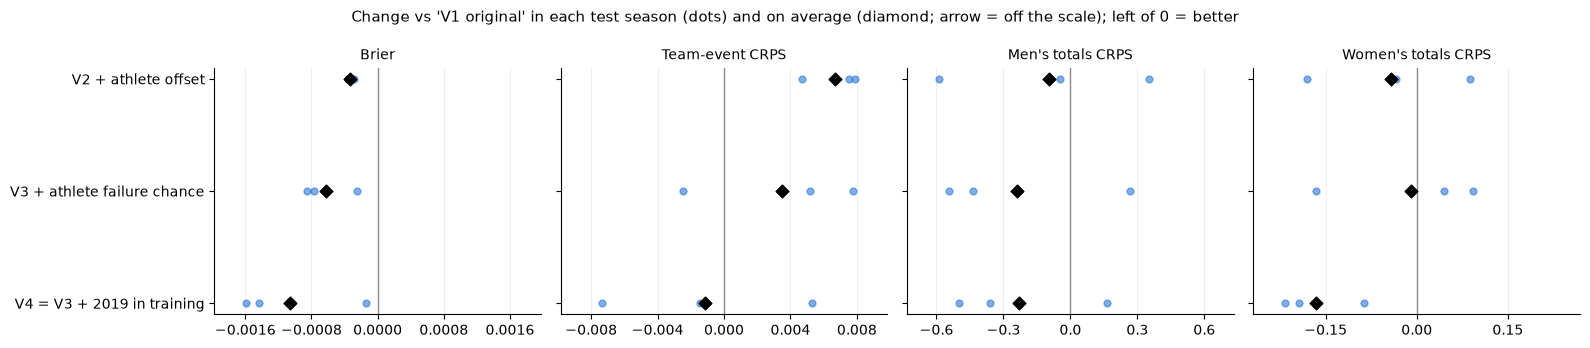

Performance-list baseline (V1 folds):


brier_plist           0.182
te_mae_plist          2.073
M_total_mae_plist    13.100
W_total_mae_plist    14.172
dtype: float64

In [75]:
step1, mean1 = run_step("1 hybrid + 2019", {
    "V1 original":                    (V1, FOLDS_NO_2019),
    "V2 + athlete offset":            (V2, FOLDS_NO_2019),
    "V3 + athlete failure chance":    (V3, FOLDS_NO_2019),
    "V4 = V3 + 2019 in training":     (V4, FOLDS),
})
print("Performance-list baseline (V1 folds):")
display(step1[step1["version"] == "V1 original"][["brier_plist", "te_mae_plist", "M_total_mae_plist", "W_total_mae_plist"]].mean().round(3))

In [76]:
check(mean1, {
    ("V1 original", "mark_mae_pct"): 2.365, ("V1 original", "M_total_crps_model"): 6.666, ("V1 original", "W_total_crps_model"): 5.721,
    ("V2 + athlete offset", "mark_mae_pct"): 2.349, ("V2 + athlete offset", "M_total_crps_model"): 6.572,
    ("V3 + athlete failure chance", "M_total_crps_model"): 6.428, ("V3 + athlete failure chance", "W_total_crps_model"): 5.712,
    ("V4 = V3 + 2019 in training", "mark_mae_pct"): 2.329, ("V4 = V3 + 2019 in training", "M_total_crps_model"): 6.435,
    ("V4 = V3 + 2019 in training", "W_total_crps_model"): 5.556,
})

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V1 original,mark_mae_pct,2.365,2.365,True
1,V1 original,M_total_crps_model,6.666,6.666,True
2,V1 original,W_total_crps_model,5.721,5.721,True
3,V2 + athlete offset,mark_mae_pct,2.349,2.349,True
4,V2 + athlete offset,M_total_crps_model,6.572,6.572,True
5,V3 + athlete failure chance,M_total_crps_model,6.428,6.428,True
6,V3 + athlete failure chance,W_total_crps_model,5.712,5.712,True
7,V4 = V3 + 2019 in training,mark_mae_pct,2.329,2.329,True
8,V4 = V3 + 2019 in training,M_total_crps_model,6.435,6.435,True
9,V4 = V3 + 2019 in training,W_total_crps_model,5.556,5.556,True


**What the regressions learned** (V4). Offset in % of the mark (+ = better than the athlete's mean); failure model in log-odds (+ = more likely to fail). Event groups are relative to sprints.

In [77]:
def coef_table(label, key, scale=1.0):
    return pd.DataFrame({t: r["ctx"]["cal"]["_pooled"][key] * scale for t, r in results[label].items()}).round(3)

print("Offset model (%):");           display(coef_table("V4 = V3 + 2019 in training", "offset_beta", 100))
print("Failure model (log-odds):");   display(coef_table("V4 = V3 + 2019 in training", "pfail_beta"))

Offset model (%):


,2023,2024,2025
intercept,1.147,0.865,0.812
group_distance,-1.385,-1.542,-1.541
group_horizontal,0.623,0.364,0.230
group_vertical,-0.279,-0.379,-0.405
group_throw,0.188,0.665,0.476
group_multi,3.345,3.716,3.575
men,-0.240,-0.231,-0.244
sb_level,-0.178,-0.148,-0.223
gap,0.293,0.272,0.306
risk,-0.055,0.087,0.135


Failure model (log-odds):


,2023,2024,2025
intercept,-2.539,-2.883,-2.880
group_distance,0.023,0.093,-0.007
group_horizontal,0.334,0.383,0.488
group_vertical,0.239,0.459,0.681
group_throw,0.563,0.792,0.633
group_multi,0.387,0.112,0.165
men,0.390,0.381,0.392
sb_level,-0.281,-0.230,-0.189
gap,0.029,-0.031,-0.027
risk,0.375,0.355,0.317


**Result**
- **V2:** mark error 2.365% → 2.349% (better in 3/3 folds). Points are mixed on its own: men's totals better in 2/3,
  team-event CRPS worse in 3/3.
- **V3:** Brier better in 3/3; men's totals 6.67 → 6.43.
- **V4:** best mark error, 2.329% (3/3); women's totals 5.72 → 5.56 (3/3).
- Effects with the same sign in every fold: top seeds fall back more (`sb_level` < 0), athletes whose best is well
  above their mean get closer to it (`gap` > 0), and athletes who fail more in the season fail more at Big West
  (`risk` > 0 in the failure model).
- With 2019 included, the bias moves from about 0 to −0.16% (athletes do slightly worse than predicted).

**Decision: keep all three (V4).**

## Step 2. Prelims + final in the 100–1500 m and hurdles
The model runs a prelim, advances the top 8, and runs a final where only finalists score. `round_rho` is how much
of an athlete's day carries over between the two races (1 = same race twice, 0 = unrelated). It is **measured**
from finalists' prelim and final marks (2019–2025); 0.3, 0.5 and 0.7 are run only to show how much it matters.

In [78]:
from scipy import stats

rounds = bm.load_bigwest(ROUNDS_PATH, CFG5)
rounds = rounds[rounds["status"] == "VALID"]
rows = []
for s in [2019, 2021, 2022, 2023, 2024, 2025]:
    conv = bm.fit_conversions(reg[reg["season"] == s], bw_events, CFG5)
    marks = bm.expand_marks(reg[reg["season"] == s], conv, bw_events, CFG5)
    prof = bm.athlete_profiles(marks, cdates[s], CFG5)
    both = (rounds[rounds["season"] == s]
            .pivot_table(index=bm.KEYS, columns="round", values="p", aggfunc="max")
            .dropna().reset_index()
            .merge(prof[bm.KEYS + ["mu", "sd"]], on=bm.KEYS))
    rows.append(both.assign(season=s))
d = pd.concat(rows)
d = d[d["event"].isin(bm.TWO_ROUND_EVENTS)]
for r in ["Preliminaries", "Finals"]:                       # each race vs the athlete's own form,
    d["z_" + r] = (d[r] - d["mu"]) / d["sd"]                # minus that round's overall conditions
    d["z_" + r] -= d.groupby(["season", "gender", "event"])["z_" + r].transform("mean")
d = d[(d[["z_Preliminaries", "z_Finals"]].abs() < 6).all(axis=1)]   # drop blowups
ROUND_RHO = round(stats.spearmanr(d["z_Preliminaries"], d["z_Finals"])[0], 2)
print(f"{len(d)} finalists | prelim-final correlation: {ROUND_RHO:.2f}")
assert ROUND_RHO == V5["round_rho"]

660 finalists | prelim-final correlation: 0.43


**Why `round_rho = 0.43`**

`round_rho` is how much of an athlete's day carries over from their prelim to their final. In the simulation each
round's noise is built from two parts:

- prelim = √ρ × (the athlete's form that day) + √(1 − ρ) × (prelim-only luck)
- final  = √ρ × (the athlete's form that day) + √(1 − ρ) × (final-only luck)

With this construction, the correlation between an athlete's prelim and final results is exactly ρ. So ρ isn't
tuned; it is **measured** as the correlation between real prelim and final results:

1. **Who:** every athlete who ran both a prelim and the final at Big West in a two-round event (100–1500 m and
   hurdles), 2019–2025: 660 finalists. 2026 is not used.
2. **What is correlated:** each race as a z-score against the athlete's own regular-season profile,
   (mark − mu) / sd. A fast athlete running fast in both rounds is expected and shouldn't count as "carry-over";
   only beating or missing their own level should.
3. **Conditions removed:** each round's average z is subtracted within each season and event. A headwind or heat
   in one final moves everyone, not one athlete's form.
4. **Blowups removed:** results more than 6 spreads from the athlete's level (falls, injuries) are dropped, so a
   few extreme races don't drive the number.
5. **Rank (Spearman) correlation,** for the same reason: it is robust to the remaining outliers.

The result is **0.43**: a bit less than half of an athlete's good or bad prelim carries into the final. The
values 0.3, 0.5 and 0.7 in the next cell are not candidates; they are there to show that the result is not
sensitive to the exact value (men's totals 6.34–6.41 across that range). Converting the rank correlation to an
ordinary (Pearson) correlation for normal data would give about 0.45; that difference is well inside this range.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V4 (one round),2.329,-0.156,0.108,1.233,6.435,5.556,0.963,0.96
"two rounds, rho 0.3",2.329,-0.156,0.108,1.232,6.337,5.521,0.963,0.96
"two rounds, rho 0.5",2.329,-0.156,0.108,1.232,6.377,5.526,0.963,0.96
"two rounds, rho 0.7",2.329,-0.156,0.108,1.232,6.410,5.539,0.963,0.96
"V5 two rounds, measured rho",2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96


Seasons where each version beats 'V4 (one round)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
"two rounds, rho 0.3",0/3,2/3,2/3,2/3,2/3,0/3,0/3
"two rounds, rho 0.5",0/3,2/3,2/3,2/3,2/3,0/3,0/3
"two rounds, rho 0.7",0/3,2/3,2/3,2/3,2/3,0/3,0/3
"V5 two rounds, measured rho",0/3,2/3,2/3,2/3,2/3,0/3,0/3


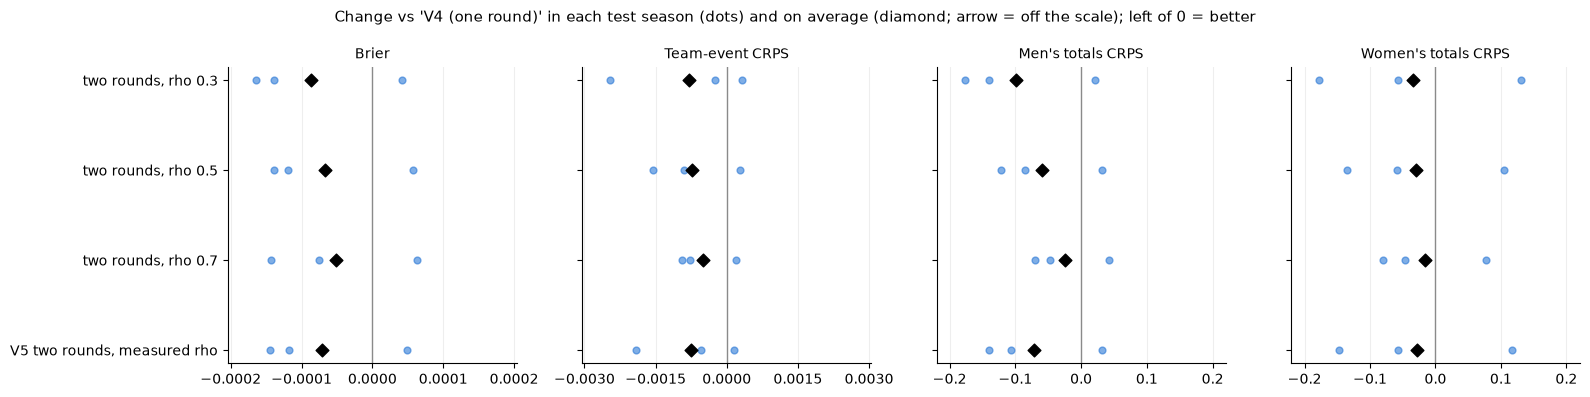

In [79]:
TWO = {**V4, "two_rounds": True}
step2, mean2 = run_step("2 two rounds", {
    "V4 (one round)":                 (V4, FOLDS),
    "two rounds, rho 0.3":            ({**TWO, "round_rho": 0.3}, FOLDS),
    "two rounds, rho 0.5":            ({**TWO, "round_rho": 0.5}, FOLDS),
    "two rounds, rho 0.7":            ({**TWO, "round_rho": 0.7}, FOLDS),
    "V5 two rounds, measured rho":    (V5, FOLDS),
})

In [80]:
display(pd.concat({"V4": by_group("V4 (one round)"), "V5": by_group("V5 two rounds, measured rho")}, axis=1))
check(mean2, {
    ("two rounds, rho 0.3", "M_total_crps_model"): 6.337, ("two rounds, rho 0.3", "W_total_crps_model"): 5.521,
    ("two rounds, rho 0.5", "M_total_crps_model"): 6.377, ("two rounds, rho 0.7", "M_total_crps_model"): 6.410,
    ("V5 two rounds, measured rho", "M_total_crps_model"): 6.364, ("V5 two rounds, measured rho", "W_total_crps_model"): 5.527,
    ("V5 two rounds, measured rho", "te_crps_model"): 1.232, ("V5 two rounds, measured rho", "mark_mae_pct"): 2.329,
})

V4                         V5                  
           athletes  brier points MAE athletes  brier points MAE
group                                                           
distance      676.0  0.112      1.136    676.0  0.112      1.131
horizontal    248.0  0.123      1.439    248.0  0.123      1.439
multi          75.0  0.116      1.436     75.0  0.116      1.437
relay         108.0  0.094      1.897    108.0  0.094      1.901
sprint        648.0  0.089      1.027    648.0  0.089      1.011
throw         436.0  0.100      1.066    436.0  0.099      1.066
vertical      186.0  0.160      1.472    186.0  0.160      1.470

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,"two rounds, rho 0.3",M_total_crps_model,6.337,6.337,True
1,"two rounds, rho 0.3",W_total_crps_model,5.521,5.521,True
2,"two rounds, rho 0.5",M_total_crps_model,6.377,6.377,True
3,"two rounds, rho 0.7",M_total_crps_model,6.410,6.410,True
4,"V5 two rounds, measured rho",M_total_crps_model,6.364,6.364,True
5,"V5 two rounds, measured rho",W_total_crps_model,5.527,5.527,True
6,"V5 two rounds, measured rho",te_crps_model,1.232,1.232,True
7,"V5 two rounds, measured rho",mark_mae_pct,2.329,2.329,True


**Result**
- Every two-round version improves team totals in 2/3 folds for men and women. With the measured value: men
  6.44 → 6.36, women 5.56 → 5.53.
- The gain is where it should be: sprint points error 1.027 → 1.011; field events and marks are unchanged.
- The value matters much less than having two rounds at all (men's totals 6.34–6.41 for rho 0.3–0.7).

**Decision: keep, with the measured `round_rho = 0.43`. This is V5, the final model.**

## Step 3. Virtual multi scores (V6a)
Decathlon and heptathlon entrants with no multi score that season get one built from their component events
(World Athletics tables), with a minimum of 4 or 5 events.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
"V6a virtual multi, min 4",2.341,-0.179,0.108,1.233,6.465,5.553,0.963,0.96
"V6a virtual multi, min 5",2.336,-0.175,0.108,1.232,6.418,5.561,0.963,0.96


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
"V6a virtual multi, min 4",1/3,1/3,1/3,0/3,1/3,0/3,0/3
"V6a virtual multi, min 5",1/3,2/3,1/3,0/3,1/3,0/3,0/3


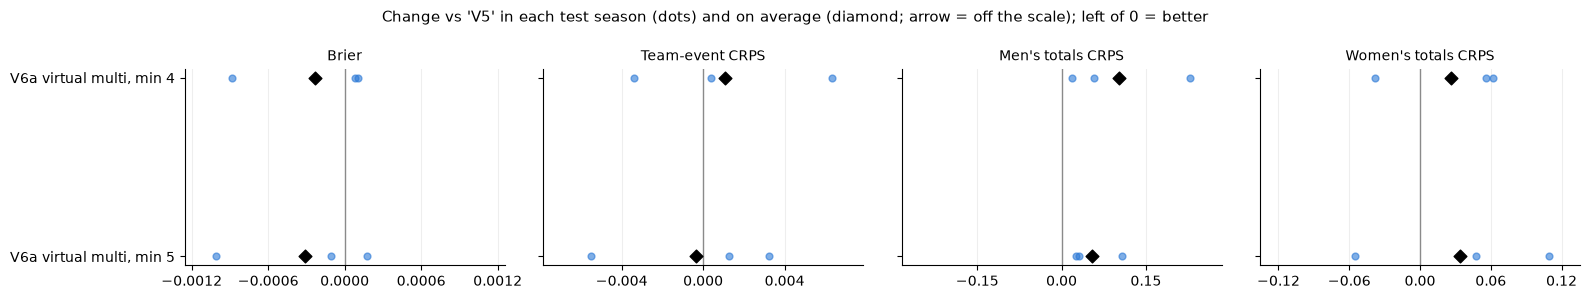

,,athletes,brier,points MAE
,group,,,
V5,multi,75.0,0.116,1.437
"V6a virtual multi, min 4",multi,75.0,0.103,1.436
"V6a virtual multi, min 5",multi,75.0,0.103,1.408


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,"V6a virtual multi, min 4",mark_mae_pct,2.341,2.341,True
1,"V6a virtual multi, min 4",M_total_crps_model,6.465,6.465,True
2,"V6a virtual multi, min 4",W_total_crps_model,5.553,5.553,True
3,"V6a virtual multi, min 5",mark_mae_pct,2.336,2.336,True
4,"V6a virtual multi, min 5",M_total_crps_model,6.418,6.418,True
5,"V6a virtual multi, min 5",W_total_crps_model,5.561,5.561,True


In [81]:
step3, mean3 = run_step("3 virtual multi", {
    "V5":                           (V5, FOLDS),
    "V6a virtual multi, min 4":     ({**V5, "virtual_multi": True, "virtual_multi_min": 4}, FOLDS),
    "V6a virtual multi, min 5":     ({**V5, "virtual_multi": True, "virtual_multi_min": 5}, FOLDS),
})
display(pd.concat({k: by_group(k).loc[["multi"]] for k in ["V5", "V6a virtual multi, min 4", "V6a virtual multi, min 5"]}))
check(mean3, {
    ("V6a virtual multi, min 4", "mark_mae_pct"): 2.341, ("V6a virtual multi, min 4", "M_total_crps_model"): 6.465,
    ("V6a virtual multi, min 4", "W_total_crps_model"): 5.553,
    ("V6a virtual multi, min 5", "mark_mae_pct"): 2.336, ("V6a virtual multi, min 5", "M_total_crps_model"): 6.418,
    ("V6a virtual multi, min 5", "W_total_crps_model"): 5.561,
})

**Result**
- It does what it was built for: the multis' own Brier improves, 0.116 → 0.103.
- But men's team totals get worse in 3/3 folds and women's in 2/3. Only 2–3 athletes a year are affected.

**Decision: not kept.** A reasonable option if the multis are reported on their own.

## Step 4. Year-to-year improvement for last-season profiles (V6b)
Entrants with no marks this season fall back on last season's profile. These versions raise that profile by the
typical season-to-season improvement (EDA), by event group or by group and level.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
V6b + change by group,2.329,-0.156,0.108,1.234,6.397,5.527,0.963,0.96
V6b + change by group/level,2.329,-0.156,0.108,1.234,6.352,5.527,0.963,0.96


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V6b + change by group,0/3,0/3,1/3,2/3,0/3,0/3,0/3
V6b + change by group/level,0/3,1/3,1/3,2/3,0/3,0/3,0/3


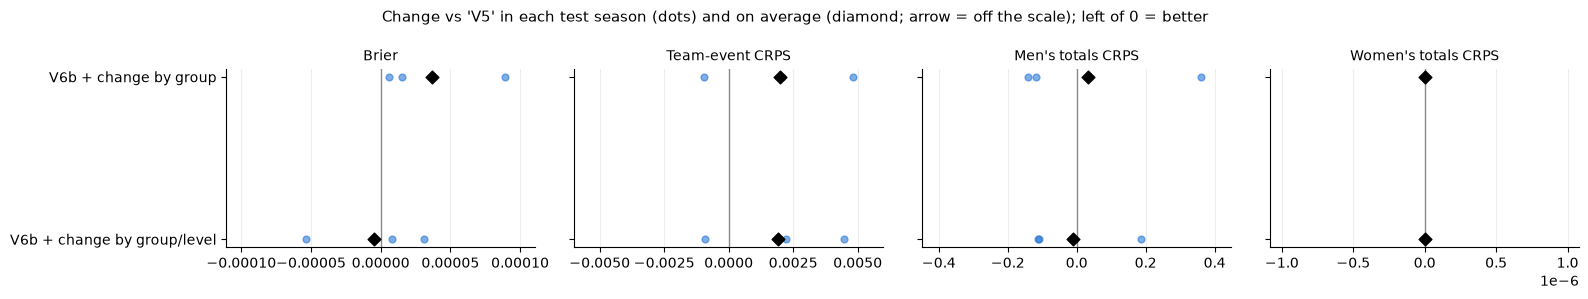

Only the athletes the change touches (using last season's profile):


,V5,V6b + change by group,V6b + change by group/level
athletes,12.00,12.00,12.0
points MAE,0.97,1.55,1.4
actual - predicted,-0.73,-1.55,-1.4


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V6b + change by group,M_total_crps_model,6.397,6.397,True
1,V6b + change by group,W_total_crps_model,5.527,5.527,True
2,V6b + change by group/level,M_total_crps_model,6.352,6.352,True
3,V6b + change by group,te_crps_model,1.234,1.234,True


In [82]:
step4, mean4 = run_step("4 prior improve", {
    "V5":                          (V5, FOLDS),
    "V6b + change by group":       ({**V5, "prior_improve": "group"}, FOLDS),
    "V6b + change by group/level": ({**V5, "prior_improve": "level"}, FOLDS),
})

def fallback_athletes(label):
    ath = pd.concat(r["athletes"] for r in results[label].values())
    a = ath[ath["source"] == "prior_season"]
    return pd.Series({"athletes": len(a), "points MAE": np.mean(np.abs(a["exp_pts"] - a["actual_pts"])),
                      "actual - predicted": np.mean(a["actual_pts"] - a["exp_pts"])}).round(2)

print("Only the athletes the change touches (using last season's profile):")
display(pd.DataFrame({k: fallback_athletes(k) for k in ["V5", "V6b + change by group", "V6b + change by group/level"]}))
check(mean4, {
    ("V6b + change by group", "M_total_crps_model"): 6.397, ("V6b + change by group", "W_total_crps_model"): 5.527,
    ("V6b + change by group/level", "M_total_crps_model"): 6.352, ("V6b + change by group", "te_crps_model"): 1.234,
})

**Result**
- Men's totals improve in 2/3 folds (6.35–6.40 vs 6.36), but women's in 0/3, team-event CRPS in 1/3 and Brier in 0–1/3.
- It touches only ~12 athletes (about 4 a year) and makes them worse: they already score less than predicted
  (−0.73 points), and the shift roughly doubles that (−1.4 to −1.55).
- The EDA improvement is real for athletes who compete every season, but these athletes had no marks this season
  (injury, redshirt, event change) and tend to perform below last season.

**Decision: not kept.**

## Step 5. Shared team form (V6c)
Every athlete on a team shares one extra "good or bad day" draw. Two data-based sizes: estimated per fold
(`"auto"`, about 0.24%) and the EDA value (0.31%).

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
"V6c team form, auto",2.329,-0.156,0.108,1.233,6.400,5.571,0.963,0.96
"V6c team form, EDA 0.31%",2.329,-0.156,0.108,1.233,6.472,5.615,0.963,0.96


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
"V6c team form, auto",0/3,1/3,1/3,1/3,1/3,0/3,0/3
"V6c team form, EDA 0.31%",0/3,1/3,1/3,1/3,1/3,0/3,0/3


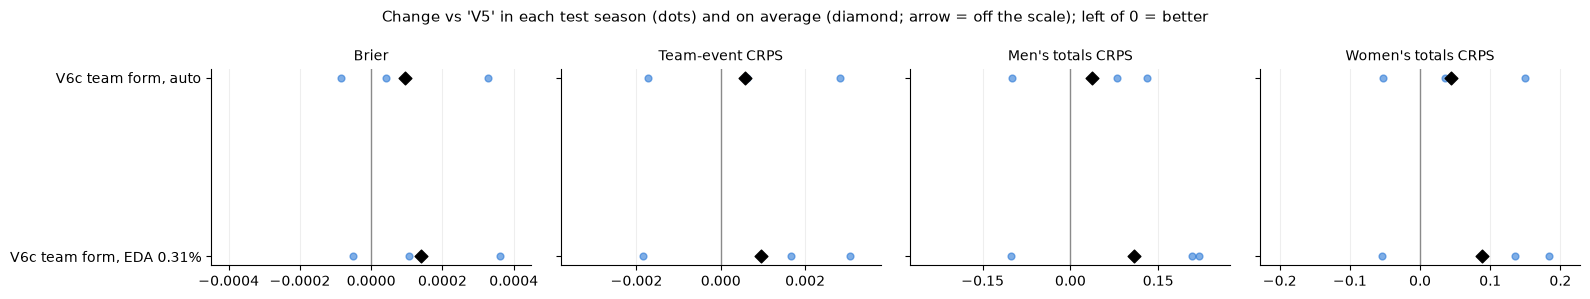

Share of actual results inside the model's 80% range (V5): team totals 83% | team-event points 92%
team_sd estimated per fold: {2023: 0.281, 2024: 0.193, 2025: 0.239} (%)
All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,"V6c team form, auto",M_total_crps_model,6.400,6.400,True
1,"V6c team form, auto",W_total_crps_model,5.571,5.571,True
2,"V6c team form, EDA 0.31%",M_total_crps_model,6.472,6.472,True
3,"V6c team form, EDA 0.31%",W_total_crps_model,5.615,5.615,True


In [83]:
step5, mean5 = run_step("5 team form", {
    "V5":                         (V5, FOLDS),
    "V6c team form, auto":        ({**V5, "team_form_sd": "auto"}, FOLDS),
    "V6c team form, EDA 0.31%":   ({**V5, "team_form_sd": 0.0031}, FOLDS),
})
tot = pd.concat(r["totals"] for r in results["V5"].values())
print("Share of actual results inside the model's 80% range (V5): team totals",
      f"{np.mean((tot['actual'] >= tot['lo80']) & (tot['actual'] <= tot['hi80'])):.0%}",
      "| team-event points", f"{step5[step5['version'] == 'V5']['te_cover80'].mean():.0%}")
print("team_sd estimated per fold:", {t: round(r["ctx"]["cal"]["_pooled"]["team_sd"] * 100, 3)
                                      for t, r in results["V6c team form, auto"].items()}, "(%)")
check(mean5, {
    ("V6c team form, auto", "M_total_crps_model"): 6.400, ("V6c team form, auto", "W_total_crps_model"): 5.571,
    ("V6c team form, EDA 0.31%", "M_total_crps_model"): 6.472, ("V6c team form, EDA 0.31%", "W_total_crps_model"): 5.615,
})

**Result**
- Team totals get worse in 2/3 folds for men and women; the larger EDA value hurts more.
- Team form doesn't move expected points, it only widens the range of team totals. The ranges are already about
  right (83% of actual totals land in the 80% range), so wider ranges are less sharp without being more accurate.

**Decision: not kept.** Part of what teammates share is probably already in the athlete-specific offset.

## Step 6. Field without entry lists (planning mode)
Entry lists are declared about a week before the meet. For planning (goals 2–3), the field can instead be every
athlete with an outdoor mark in the event (plus 5000 m runners in the 10,000 m). Evaluation still uses the real results.

The **baseline** is shown here too: a TFRRS-style performance-list meet calculator that ranks everyone with an
outdoor mark by season best (no conversions, wind-aided marks included) and scores places 1–8.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5 (actual entrants),2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
V5 everyone with outdoor marks,2.318,-0.279,0.064,1.330,8.212,8.535,0.943,0.939


Seasons where each version beats 'V5 (actual entrants)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V5 everyone with outdoor marks,2/3,3/3,0/3,1/3,0/3,1/3,1/3


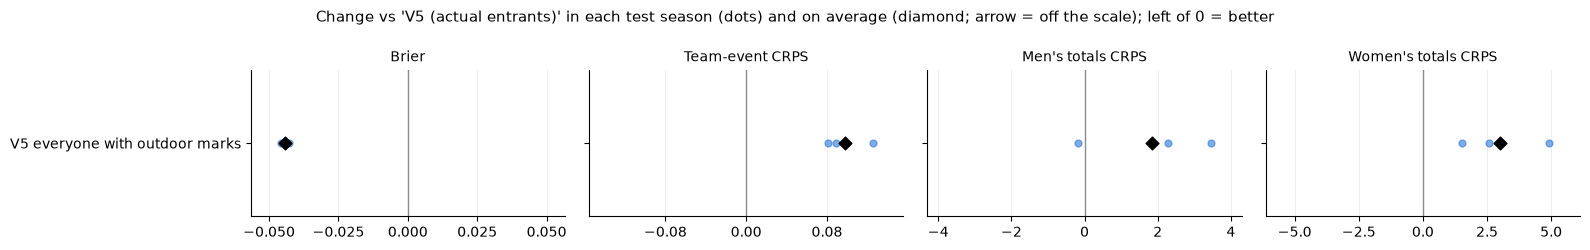

Model (median of the simulations) vs the performance list, average points off:


,te_mae_model,te_mae_plist,M_total_mae_model,M_total_mae_plist,W_total_mae_model,W_total_mae_plist,M_spearman_model,M_spearman_plist,W_spearman_model,W_spearman_plist
version,,,,,,,,,,
V5 (actual entrants),1.712,2.073,9.011,13.1,7.397,14.172,0.963,0.914,0.960,0.919
V5 everyone with outdoor marks,1.860,2.073,10.800,13.1,11.465,14.172,0.943,0.914,0.939,0.919


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V5 everyone with outdoor marks,mark_mae_pct,2.318,2.318,True
1,V5 everyone with outdoor marks,te_crps_model,1.330,1.330,True
2,V5 everyone with outdoor marks,M_total_crps_model,8.212,8.212,True
3,V5 everyone with outdoor marks,W_total_crps_model,8.535,8.535,True


In [84]:
step6, mean6 = run_step("6 field mode", {
    "V5 (actual entrants)":            (V5, FOLDS),
    "V5 everyone with outdoor marks":  ({**V5, "field_mode": "everyone"}, FOLDS),
})
VS_COLS = ["te_mae_model", "te_mae_plist", "M_total_mae_model", "M_total_mae_plist",
           "W_total_mae_model", "W_total_mae_plist", "M_spearman_model", "M_spearman_plist", "W_spearman_model", "W_spearman_plist"]
print("Model (median of the simulations) vs the performance list, average points off:")
display(step6.groupby("version", sort=False)[VS_COLS].mean().round(3))
check(mean6, {
    ("V5 everyone with outdoor marks", "mark_mae_pct"): 2.318, ("V5 everyone with outdoor marks", "te_crps_model"): 1.330,
    ("V5 everyone with outdoor marks", "M_total_crps_model"): 8.212, ("V5 everyone with outdoor marks", "W_total_crps_model"): 8.535,
})

**Result**
- With entry lists the model is clearly better: team totals 6.4 / 5.5 vs 8.2 / 8.5 CRPS.
- Without entry lists it still beats the performance list, which uses the same information (team totals off by
  10.8 / 11.5 vs 13.1 / 14.2 points).
- Brier is not comparable between the two modes: the bigger field adds many easy non-scorers.

**Decision: keep both.** `"entrants"` is the default; `"everyone"` is the planning mode for goals 2–3.

# Part 2. 2026 holdout
## Step 7. Final model on 2026
Trained on 2019 and 2021–2025, tested on 2026, run once. No settings were changed after seeing these numbers.

In [85]:
train, test = FINAL_FOLD
final = bm.run_fold(reg, bw, train, test, cdates, bw_events, {**CFG, **V5}, verbose=False)
final_everyone = bm.run_fold(reg, bw, train, test, cdates, bw_events, {**CFG, **V5, "field_mode": "everyone"}, verbose=False)
results["2026 final"], results["2026 final, everyone"] = {2026: final}, {2026: final_everyone}

rows = {}
for label, s in [("model, entrants", final["summary"]), ("model, everyone", final_everyone["summary"])]:
    rows[label] = {"mark MAE %": s["mark_mae_pct"], "mark bias %": s["mark_bias_pct"], "Brier": s["brier_model"],
                   "team-event points off": s["te_mae_model"], "men's totals off": s["M_total_mae_model"],
                   "women's totals off": s["W_total_mae_model"], "men's ranking": s["M_spearman_model"],
                   "women's ranking": s["W_spearman_model"]}
s = final["summary"]
rows["performance list"] = {"Brier": s["brier_plist"], "team-event points off": s["te_mae_plist"],
                            "men's totals off": s["M_total_mae_plist"], "women's totals off": s["W_total_mae_plist"],
                            "men's ranking": s["M_spearman_plist"], "women's ranking": s["W_spearman_plist"]}
holdout = pd.DataFrame(rows)
display(holdout.round(3))

recorded_2026 = {("model, entrants", "mark MAE %"): 2.02, ("model, entrants", "Brier"): 0.112,
                 ("model, entrants", "team-event points off"): 1.71, ("model, entrants", "men's totals off"): 8.0,
                 ("model, entrants", "women's totals off"): 13.91, ("model, everyone", "men's totals off"): 10.5,
                 ("model, everyone", "women's totals off"): 13.45, ("performance list", "men's totals off"): 14.2,
                 ("performance list", "women's totals off"): 10.46, ("performance list", "Brier"): 0.185}
ok = {k: abs(holdout.loc[k[1], k[0]] - v) <= 0.006 + 0.005 * abs(v) for k, v in recorded_2026.items()}
print("All recorded 2026 numbers reproduced." if all(ok.values()) else f"MISMATCH: {[k for k, v in ok.items() if not v]}")

,"model, entrants","model, everyone",performance list
mark MAE %,2.020,2.029,NaN
mark bias %,-0.180,-0.272,NaN
Brier,0.112,0.063,0.185
team-event points off,1.710,1.842,1.898
men's totals off,8.000,10.500,14.200
women's totals off,13.909,13.455,10.455
men's ranking,1.000,0.927,0.891
women's ranking,0.902,0.925,0.936


All recorded 2026 numbers reproduced.


In [86]:
print("2026 team totals (final model, entrants):")
display(final["totals"].sort_values(["gender", "exp_pts"], ascending=[True, False])
        [["gender", "team", "exp_pts", "med", "lo80", "hi80", "p_win", "plist_pts", "actual"]].round(1))

2026 team totals (final model, entrants):


,gender,team,exp_pts,med,lo80,hi80,p_win,plist_pts,actual
9,M,CAL POLY,181.4,182.0,164.0,199.0,1.0,168.0,201.5
0,M,CAL ST. FULLERTON,141.2,141.0,122.0,160.0,0.0,146.0,152.0
1,M,LONG BEACH ST.,119.4,119.0,101.0,138.0,0.0,115.0,114.0
4,M,UC IRVINE,80.8,81.0,66.0,96.0,0.0,67.0,84.5
6,M,UC SAN DIEGO,76.0,76.0,61.0,92.0,0.0,66.0,77.5
3,M,UC SANTA BARBARA,73.6,73.0,59.0,88.1,0.0,72.0,66.5
2,M,CSUN,67.3,67.0,53.0,82.0,0.0,90.0,46.0
5,M,UC RIVERSIDE,39.4,39.0,27.0,52.0,0.0,39.0,44.0
7,M,UC DAVIS,22.7,23.0,15.0,30.0,0.0,32.0,17.0
8,M,CSU BAKERSFIELD,16.7,16.0,10.0,25.0,0.0,18.0,15.0


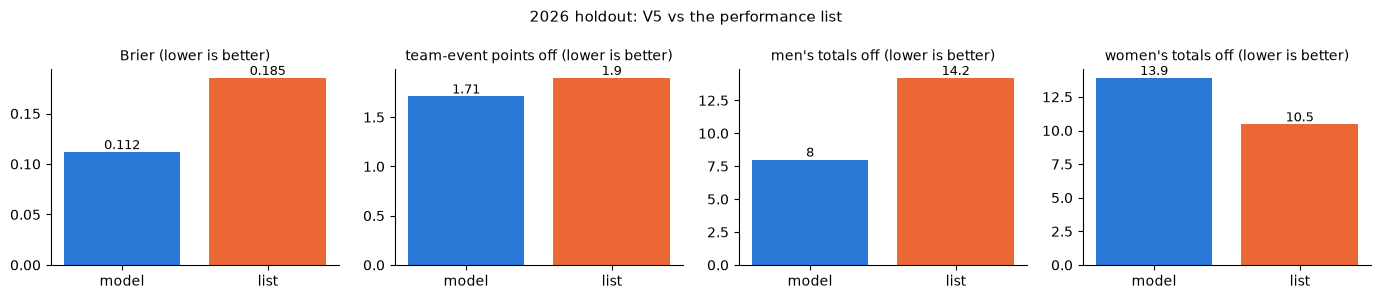

In [87]:
# The holdout at a glance: model (V5) vs the performance list on 2026
cmp = holdout.loc[["Brier", "team-event points off", "men's totals off", "women's totals off"],
                  ["model, entrants", "performance list"]]
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (name, row) in zip(axes, cmp.iterrows()):
    ax.bar(["model", "list"], row.values, color=[BLUE, ORANGE])
    ax.set_title(f"{name} (lower is better)", fontsize=10)
    for x, v in enumerate(row.values):
        ax.text(x, v, f"{v:.3g}", ha="center", va="bottom", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("2026 holdout: V5 vs the performance list", fontsize=11)
fig.tight_layout(); plt.show()

**Result**
- Against the performance list, the model is better at who scores (Brier 0.112 vs 0.185), team points per event
  (1.71 vs 1.90 off) and men's totals (8.0 vs 14.2 off with entry lists; 10.5 without), and ranks all ten men's
  teams correctly.
- Women's 2026 is the exception: the list was closer on totals (10.5 vs 13.5–13.9 off) and ranking (0.94 vs 0.90),
  driven by several large team departures from regular-season form (UCSB, Hawaii, Bakersfield, Fullerton).

# Part 3. Checking the hand-set settings
## Step 8. Settings fixed before this workflow
These were set when the model was first built, not chosen by a test. Each is either **estimated from the training
seasons** (`"auto"` or a direct measurement) or **sensitivity-checked** across reasonable values.

These checks were run after the 2026 test, so the final model is only changed for a clear difference. 8g runs one
combined version on 2026 as a labelled after-the-fact check.

### 8a. Recency half-life (`half_life_days = 45`)
`"auto"` finds, from each fold's training seasons, the half-life whose weighted average lands closest to athletes'
Big West marks.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5 (45 days),2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
half-life from the data,2.334,-0.144,0.108,1.240,6.481,5.576,0.963,0.952


Seasons where each version beats 'V5 (45 days)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
half-life from the data,1/3,1/3,0/3,2/3,1/3,0/3,0/3


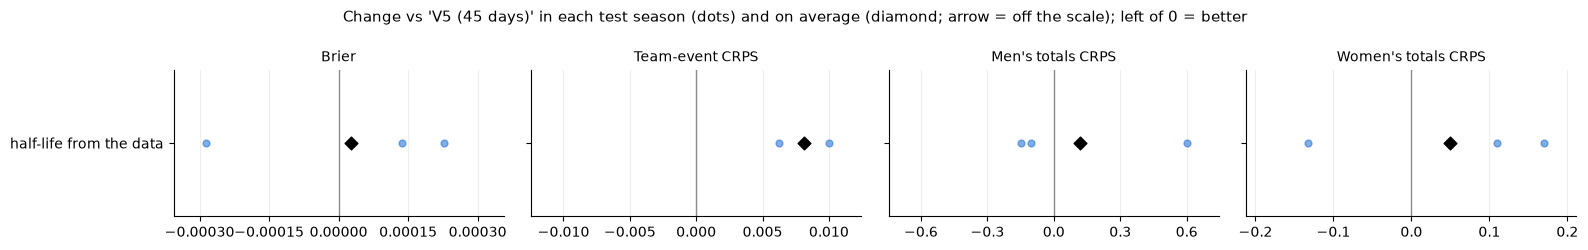

estimated half-life per fold (days): {2023: 19.3, 2024: 20.7, 2025: 20.8}
All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,half-life from the data,mark_mae_pct,2.334,2.334,True
1,half-life from the data,M_total_crps_model,6.481,6.481,True
2,half-life from the data,W_total_crps_model,5.576,5.576,True


In [88]:
step8a, mean8a = run_step("8a half-life", {
    "V5 (45 days)":                (V5, FOLDS),
    "half-life from the data":     ({**V5, "half_life_days": "auto"}, FOLDS),
})
print("estimated half-life per fold (days):",
      {t: round(r["ctx"]["cfg"]["half_life_days"], 1) for t, r in results["half-life from the data"].items()})
check(mean8a, {("half-life from the data", "mark_mae_pct"): 2.334,
               ("half-life from the data", "M_total_crps_model"): 6.481,
               ("half-life from the data", "W_total_crps_model"): 5.576})

**Result**
- The data puts the half-life at about 20 days (19.3, 20.7, 20.8).
- In the full model it is worse than 45: team-event CRPS worse in 3/3 folds, mark error better in only 1/3, women's
  totals worse in 2/3. Men's totals are better in 2/3 folds but worse on average (6.48 vs 6.36).
- The half-life also sets how many marks count toward each athlete's spread and the `gap` feature, and the full
  model benefits from more history than the average alone.

**Decision: keep 45 days.**

### 8b. Spread shrinkage (`k_spread = 4`)
`"auto"` finds, from each fold's training seasons, the shrinkage that best predicts how variable athletes are at Big West.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5 (k_spread 4),2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
k_spread from the data,2.327,-0.158,0.107,1.230,6.373,5.504,0.963,0.964


Seasons where each version beats 'V5 (k_spread 4)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
k_spread from the data,2/3,3/3,2/3,1/3,2/3,0/3,1/3


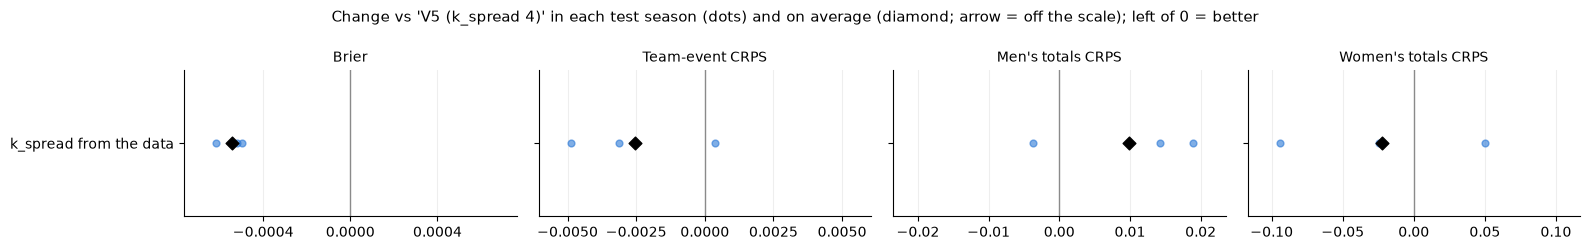

estimated k_spread per fold: {2023: 14.7, 2024: 15.7, 2025: 16.2}
All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,k_spread from the data,mark_mae_pct,2.327,2.327,True
1,k_spread from the data,M_total_crps_model,6.373,6.373,True
2,k_spread from the data,W_total_crps_model,5.504,5.504,True


In [89]:
step8b, mean8b = run_step("8b spread shrinkage", {
    "V5 (k_spread 4)":             (V5, FOLDS),
    "k_spread from the data":      ({**V5, "k_spread": "auto"}, FOLDS),
})
print("estimated k_spread per fold:",
      {t: round(r["ctx"]["cfg"]["k_spread"], 1) for t, r in results["k_spread from the data"].items()})
check(mean8b, {("k_spread from the data", "mark_mae_pct"): 2.327,
               ("k_spread from the data", "M_total_crps_model"): 6.373,
               ("k_spread from the data", "W_total_crps_model"): 5.504})

**Result**
- The data puts it at about 15 (14.7, 15.7, 16.2): an athlete's own spread says less about their Big West
  variability than the event's typical spread does.
- In the full model the results are essentially the same (team totals within 0.03 points). Brier is better in 3/3
  folds; mark error, team-event CRPS and women's totals in 2/3; men's totals worse in 2/3.

**Decision: keep 4.** Not changed after the 2026 test for a difference this small.

### 8c. Conversion weight (`conv_weight = 0.5`)
How much a converted mark (e.g. a 60 m turned into a 100 m) counts compared with a direct one. Inverse-variance
weighting gives a data-based weight for each conversion: race-to-race spread² / (spread² + conversion error²).

In [90]:
conv_check = bm.fit_conversions(reg[reg["season"].isin(FOLDS[-1][0])], bw_events, CFG5)
sigma = conv_check.pop("_sigma")
conv_table = pd.DataFrame([{"gender": g, "from": s, "to": t, "athletes": c["n"], "dropped": c["n_dropped"],
                            "slope": c["b"], "conversion error %": 100 * c["resid_sd"],
                            "race-to-race sd %": 100 * sigma.get((g, t), np.nan), "inverse-variance weight": c["w_iv"]}
                           for (g, s, t), c in conv_check.items()]).sort_values("athletes", ascending=False)
display(conv_table.round(2))
print("median inverse-variance weight:", round(conv_table["inverse-variance weight"].median(), 2))

,gender,from,to,athletes,dropped,slope,conversion error %,race-to-race sd %,inverse-variance weight
1,W,1500,5000,276,0,0.99,2.73,1.38,0.20
16,M,1500,5000,258,1,0.75,2.70,1.32,0.19
2,W,3000,1500,212,2,0.85,2.76,1.42,0.21
3,W,3000,5000,204,1,1.01,2.12,1.38,0.30
11,W,Mile,1500,165,0,0.62,2.74,1.42,0.21
17,M,3000,1500,160,0,0.65,2.49,1.36,0.23
18,M,3000,5000,154,0,0.75,2.00,1.32,0.30
7,W,60,100,150,0,1.00,1.77,1.07,0.27
10,W,60H,100H,136,3,0.93,2.44,1.84,0.36
26,M,Mile,1500,103,0,0.63,2.10,1.36,0.30


median inverse-variance weight: 0.25


Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5 (conv_weight 0.5),2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
inverse-variance weight,2.340,-0.143,0.108,1.236,6.377,5.526,0.963,0.96
conv_weight 0.25,2.338,-0.145,0.108,1.235,6.365,5.513,0.963,0.96
conv_weight 1.0,2.328,-0.154,0.108,1.232,6.376,5.612,0.963,0.96


Seasons where each version beats 'V5 (conv_weight 0.5)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
inverse-variance weight,0/3,1/3,0/3,2/3,1/3,0/3,0/3
conv_weight 0.25,0/3,1/3,1/3,2/3,1/3,0/3,0/3
conv_weight 1.0,2/3,1/3,2/3,2/3,1/3,0/3,0/3


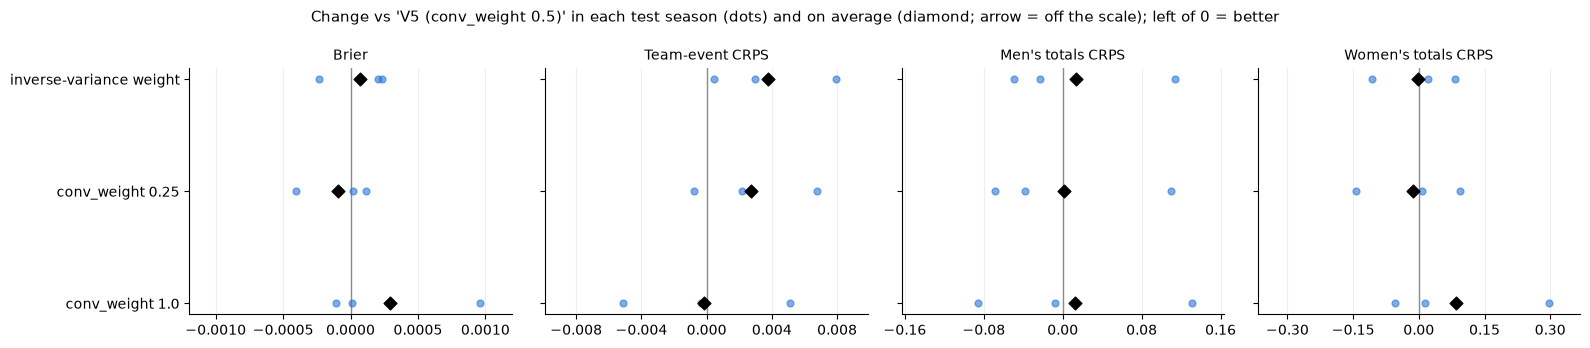

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,inverse-variance weight,mark_mae_pct,2.340,2.340,True
1,inverse-variance weight,M_total_crps_model,6.377,6.377,True
2,inverse-variance weight,W_total_crps_model,5.526,5.526,True


In [91]:
step8c, mean8c = run_step("8c conversion weight", {
    "V5 (conv_weight 0.5)":        (V5, FOLDS),
    "inverse-variance weight":     ({**V5, "conv_weight": "auto"}, FOLDS),
    "conv_weight 0.25":            ({**V5, "conv_weight": 0.25}, FOLDS),
    "conv_weight 1.0":             ({**V5, "conv_weight": 1.0}, FOLDS),
})
check(mean8c, {("inverse-variance weight", "mark_mae_pct"): 2.340,
               ("inverse-variance weight", "M_total_crps_model"): 6.377,
               ("inverse-variance weight", "W_total_crps_model"): 5.526})

**Result**
- The data-based weight is about 0.25 (conversion error ~2–2.7% vs ~1.3% race-to-race spread).
- In the full model it is slightly worse: mark error worse in 3/3 folds, team totals mixed.
- The weight only matters when an athlete has both direct and converted marks in an event. With only converted
  marks (about 1 in 6 athlete-events) it cancels out of the average.

**Decision: keep 0.5.**

### 8d. Fitting the conversion lines (`min_conv_pairs = 10`, `conv_trim_z = 4`)
The minimum number of athletes needed to fit a conversion line, and the outlier cut-off when fitting it.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
"V5 (min pairs 10, trim 4)",2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
min pairs 5,2.336,-0.145,0.108,1.237,6.403,5.509,0.963,0.960
min pairs 20,2.330,-0.153,0.108,1.234,6.362,5.584,0.963,0.960
min pairs 30,2.343,-0.154,0.109,1.240,6.326,5.616,0.963,0.947
trim off,2.332,-0.147,0.108,1.233,6.382,5.573,0.963,0.960
trim 3,2.331,-0.155,0.108,1.231,6.344,5.505,0.963,0.960
trim 6,2.331,-0.154,0.108,1.232,6.358,5.547,0.963,0.960


Seasons where each version beats 'V5 (min pairs 10, trim 4)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
min pairs 5,0/3,2/3,0/3,1/3,1/3,0/3,0/3
min pairs 20,0/3,1/3,1/3,2/3,2/3,0/3,0/3
min pairs 30,1/3,2/3,2/3,3/3,1/3,0/3,0/3
trim off,0/3,1/3,1/3,2/3,0/3,0/3,0/3
trim 3,1/3,1/3,2/3,1/3,2/3,0/3,0/3
trim 6,0/3,1/3,1/3,1/3,1/3,0/3,0/3


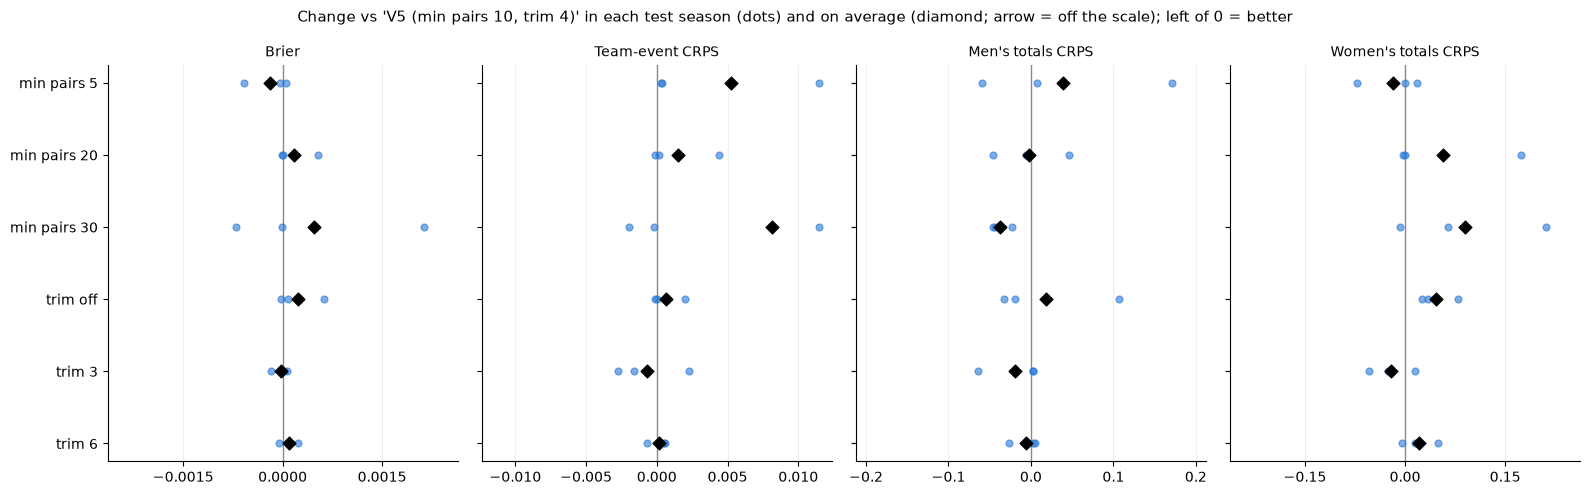

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,min pairs 5,M_total_crps_model,6.403,6.403,True
1,min pairs 30,W_total_crps_model,5.616,5.616,True
2,trim off,M_total_crps_model,6.382,6.382,True
3,trim 3,W_total_crps_model,5.505,5.505,True


In [92]:
step8d, mean8d = run_step("8d conversion fitting", {
    "V5 (min pairs 10, trim 4)":   (V5, FOLDS),
    "min pairs 5":                 ({**V5, "min_conv_pairs": 5}, FOLDS),
    "min pairs 20":                ({**V5, "min_conv_pairs": 20}, FOLDS),
    "min pairs 30":                ({**V5, "min_conv_pairs": 30}, FOLDS),
    "trim off":                    ({**V5, "conv_trim_z": 0}, FOLDS),
    "trim 3":                      ({**V5, "conv_trim_z": 3}, FOLDS),
    "trim 6":                      ({**V5, "conv_trim_z": 6}, FOLDS),
})
check(mean8d, {("min pairs 5", "M_total_crps_model"): 6.403, ("min pairs 30", "W_total_crps_model"): 5.616,
               ("trim off", "M_total_crps_model"): 6.382, ("trim 3", "W_total_crps_model"): 5.505})

**Result**
- Results barely change for a minimum of 5–30 athletes or a cut-off of 3–6.
- Trimming removes at most 3 points from any line (see the table in 8c); turning it off is slightly worse.

**Decision: keep both.**

### 8e. Calibration settings
`cal_prior_n` (shrinkage of each event's calibration toward the all-event value), `blowup_z` (a Big West result this
far below prediction counts as a failure), `dns_as_fail`, `p_fail_source` (failure rate for athletes without the
logistic prediction), `ridge` and `mu_shrink`. First, two measurements from the championship residuals:
(a) where results stop looking like normal variation, and (b) the empirical-Bayes value of `cal_prior_n`.

In [93]:
from scipy.stats import norm

TR = [2019, 2021, 2022, 2023, 2024, 2025]                      # never 2026
conv_r = bm.fit_conversions(reg[reg["season"].isin(TR)], bw_events, CFG5)
marks_r = bm.expand_marks(reg[reg["season"].isin(TR)], conv_r, bw_events, CFG5)
rows = []
for s in TR:
    prof = bm.athlete_profiles(marks_r[marks_r["season"] == s], cdates[s], CFG5)
    act = bw[(bw["season"] == s) & (bw["status"] == "VALID")][bm.KEYS + ["p"]].rename(columns={"p": "p_act"})
    rows.append(act.merge(prof[bm.KEYS + ["mu", "sd"]], on=bm.KEYS).assign(season=s))
resid = pd.concat(rows, ignore_index=True)
resid["res"] = resid["p_act"] - resid["mu"]
z = []
for _, d in resid.groupby(["gender", "event"]):                   # same robust z as fit_calibration
    zz = (d["res"] - d["res"].median()) / d["sd"]
    z.append(zz / bm._mad_sd(zz))
resid["z"] = pd.concat(z)

# (a) how far below prediction stops looking like normal variation?
tail = pd.DataFrame({k: {"results": int((resid["z"] < -k).sum()), "if normal": len(resid) * norm.cdf(-k)}
                     for k in [2, 3, 4, 5, 6]}).T
tail["ratio"] = tail["results"] / tail["if normal"]
print(f"{len(resid)} championship results")
display(tail.round(2))

# (b) empirical-Bayes shrinkage for per-event offsets (blowups removed)
ok = resid[resid["z"] >= -4]
ev_stats = ok.groupby(["gender", "event"])["res"].agg(["mean", "var", "size"])
ev_stats = ev_stats[ev_stats["size"] >= 5]
tau2 = ev_stats["mean"].var() - np.mean(ev_stats["var"] / ev_stats["size"])    # true between-event variance
n0 = np.mean(ev_stats["var"]) / tau2
print(f"within-event variance {1e4 * ev_stats['var'].mean():.2f} %^2 | between-event {1e4 * tau2:.2f} %^2 "
      f"| empirical-Bayes cal_prior_n = {n0:.1f}")

4176 championship results


,results,if normal,ratio
2,256.0,95.00,2.69
3,111.0,5.64,19.69
4,64.0,0.13,483.90
5,38.0,0.00,31744.52
6,30.0,0.00,7281571.06


within-event variance 9.85 %^2 | between-event 2.14 %^2 | empirical-Bayes cal_prior_n = 4.6


Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
cal_prior_n 5 (emp. Bayes),2.333,-0.159,0.108,1.233,6.350,5.520,0.963,0.960
cal_prior_n 2,2.338,-0.162,0.108,1.234,6.322,5.511,0.963,0.960
cal_prior_n 16,2.321,-0.151,0.108,1.232,6.418,5.563,0.963,0.960
blowup_z 3,2.334,-0.253,0.108,1.232,6.430,5.549,0.963,0.960
blowup_z 5,2.332,-0.095,0.108,1.232,6.348,5.508,0.963,0.960
blowups off,2.894,-2.231,0.187,1.629,12.528,8.047,0.975,0.917
dns_as_fail False,2.329,-0.156,0.108,1.232,6.351,5.525,0.963,0.960
p_fail_source athlete,2.329,-0.156,0.108,1.228,6.414,5.586,0.963,0.960


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
cal_prior_n 5 (emp. Bayes),0/3,3/3,1/3,2/3,3/3,0/3,0/3
cal_prior_n 2,0/3,3/3,0/3,2/3,2/3,0/3,0/3
cal_prior_n 16,3/3,1/3,1/3,0/3,1/3,0/3,0/3
blowup_z 3,0/3,0/3,1/3,0/3,1/3,0/3,0/3
blowup_z 5,0/3,3/3,2/3,2/3,2/3,0/3,0/3
blowups off,0/3,0/3,0/3,0/3,0/3,2/3,0/3
dns_as_fail False,0/3,3/3,3/3,3/3,3/3,0/3,0/3
p_fail_source athlete,0/3,1/3,3/3,1/3,1/3,0/3,0/3
p_fail_source blend,0/3,1/3,3/3,2/3,1/3,0/3,0/3
ridge 0.1,0/3,2/3,2/3,3/3,2/3,0/3,0/3


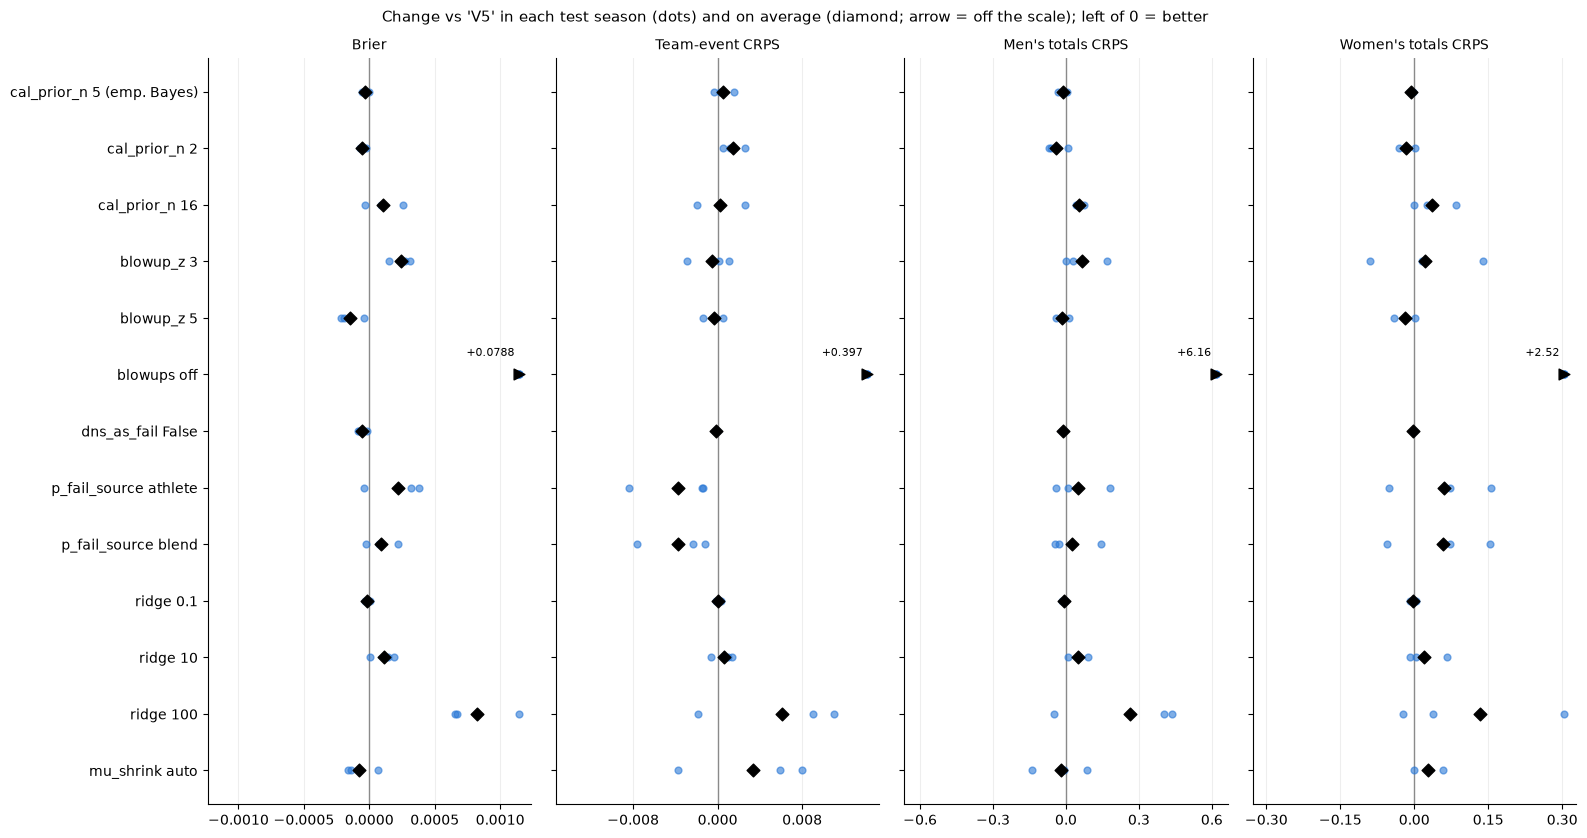

All recorded numbers reproduced.
mu_shrink estimated per fold: {2023: 0.065, 2024: 0.064, 2025: 0.086}


In [94]:
step8e, mean8e = run_step("8e calibration settings", {
    "V5":                         (V5, FOLDS),
    "cal_prior_n 5 (emp. Bayes)": ({**V5, "cal_prior_n": 5}, FOLDS),
    "cal_prior_n 2":              ({**V5, "cal_prior_n": 2}, FOLDS),
    "cal_prior_n 16":             ({**V5, "cal_prior_n": 16}, FOLDS),
    "blowup_z 3":                 ({**V5, "blowup_z": 3}, FOLDS),
    "blowup_z 5":                 ({**V5, "blowup_z": 5}, FOLDS),
    "blowups off":                ({**V5, "blowup_z": 0}, FOLDS),
    "dns_as_fail False":          ({**V5, "dns_as_fail": False}, FOLDS),
    "p_fail_source athlete":      ({**V5, "p_fail_source": "athlete"}, FOLDS),
    "p_fail_source blend":        ({**V5, "p_fail_source": "blend"}, FOLDS),
    "ridge 0.1":                  ({**V5, "ridge": 0.1}, FOLDS),
    "ridge 10":                   ({**V5, "ridge": 10}, FOLDS),
    "ridge 100":                  ({**V5, "ridge": 100}, FOLDS),
    "mu_shrink auto":             ({**V5, "mu_shrink": "auto"}, FOLDS),
})
check(mean8e, {("cal_prior_n 5 (emp. Bayes)", "M_total_crps_model"): 6.350,
               ("cal_prior_n 5 (emp. Bayes)", "W_total_crps_model"): 5.520,
               ("blowups off", "M_total_crps_model"): 12.528, ("blowup_z 3", "M_total_crps_model"): 6.430,
               ("dns_as_fail False", "M_total_crps_model"): 6.351, ("p_fail_source athlete", "M_total_crps_model"): 6.414,
               ("ridge 100", "M_total_crps_model"): 6.627, ("mu_shrink auto", "W_total_crps_model"): 5.556})
print("mu_shrink estimated per fold:", {t: round(r["ctx"]["cal"]["_pooled"]["mu_shrink"], 3)
                                        for t, r in results["mu_shrink auto"].items()})

**Result and decisions** (all kept)
- **`blowup_z = 4`:** past about −3 robust spreads, results stop looking like normal variation (20× more than a
  normal distribution at −3, 480× at −4). At 4, normal variation would give fewer than one false flag in 4,176
  results. Turning blowups off is far worse (men's totals 6.4 → 12.5); 5 is slightly better in most folds
  (6.35 / 5.51 vs 6.36 / 5.53) and 3 is worse.
- **`cal_prior_n = 8`:** empirical Bayes gives about 5 (within-event variance 9.85 vs between-event 2.14 %²). With 5,
  team totals are slightly better (2/3 folds men, 3/3 women) but mark error is worse in 3/3, with differences under
  0.02 points.
- **`dns_as_fail = True`:** not counting scratches is slightly better in 3/3 folds, by under 0.02 points. Kept because
  scratches are a real outcome in the planning mode.
- **`p_fail_source = "bigwest"`:** the athlete-based and blended rates are worse on team totals but better on
  team-event CRPS in 3/3 folds (1.228 vs 1.232): a trade-off.
- **`ridge = 1`:** 0.1 is marginally better (under 0.01 points); 10 and 100 are worse (a heavy penalty flattens the
  athlete effects).
- **`mu_shrink = 0`:** estimated at only ~0.07, with mixed results; the offset regression's `sb_level` term already
  captures top seeds falling back.

None of the small gains justified changing the model after the 2026 test.

### 8f. Athletes with no marks (`impute_q = "auto"`, `impute_sd_mult = 1.5`)
Entrants with no regular-season profile (2–6 a year) are placed at a field quantile (`impute_q`, already learned
from the training seasons) with a wide spread (`impute_sd_mult` × the field's median spread). First, how widely
these athletes' results actually scatter:

In [95]:
def imputed_scatter(train):
    """How far no-profile entrants' Big West results fall from the imputed level, in field-median spreads."""
    conv_i = bm.fit_conversions(reg[reg["season"].isin(train)], bw_events, CFG5)
    marks_i = bm.expand_marks(reg[reg["season"].isin(train)], conv_i, bw_events, CFG5)
    z = []
    for s in train:
        prof = bm.athlete_profiles(marks_i[marks_i["season"] == s], cdates[s], CFG5)
        ent = bw[(bw["season"] == s) & ~bw["event"].isin(bm.RELAYS)]
        for _, d in ent.groupby(["gender", "event"]):
            f = d[bm.KEYS].merge(prof[bm.KEYS + ["mu", "sd"]], on=bm.KEYS, how="left")
            if f["mu"].notna().sum() < 3:
                continue
            level, spread = f["mu"].quantile(0.4), f["sd"].median()
            nohist = d[d["status"] == "VALID"].merge(f[f["mu"].isna()][bm.KEYS], on=bm.KEYS)
            z += list((nohist["p"] - level) / spread)
    z = np.array(z)
    return pd.Series({"athletes": len(z), "sd": np.std(z, ddof=1),
                      "robust sd": 1.4826 * np.median(np.abs(z - np.median(z)))})

display(pd.DataFrame({test: imputed_scatter(train) for train, test in FOLDS}).T.round(2))

,athletes,sd,robust sd
2023,40.0,5.08,3.11
2024,47.0,5.54,3.04
2025,56.0,5.29,2.78


Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
"V5 (auto, sd x1.5)",2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
impute_q 0.1,2.329,-0.156,0.108,1.235,6.400,5.578,0.963,0.96
impute_q 0.2,2.329,-0.156,0.108,1.234,6.390,5.563,0.963,0.96
impute_q 0.4,2.329,-0.156,0.108,1.232,6.369,5.529,0.963,0.96
impute_sd_mult 1.0,2.329,-0.156,0.108,1.233,6.390,5.553,0.963,0.96
impute_sd_mult 2.0,2.329,-0.156,0.108,1.231,6.335,5.503,0.963,0.96
impute_sd_mult 3.0,2.329,-0.156,0.108,1.230,6.286,5.470,0.963,0.96


Seasons where each version beats 'V5 (auto, sd x1.5)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
impute_q 0.1,0/3,2/3,1/3,0/3,1/3,0/3,0/3
impute_q 0.2,0/3,2/3,1/3,0/3,1/3,0/3,0/3
impute_q 0.4,0/3,2/3,0/3,0/3,1/3,0/3,0/3
impute_sd_mult 1.0,0/3,2/3,0/3,0/3,1/3,0/3,0/3
impute_sd_mult 2.0,0/3,1/3,2/3,2/3,2/3,0/3,0/3
impute_sd_mult 3.0,0/3,1/3,2/3,2/3,1/3,0/3,0/3


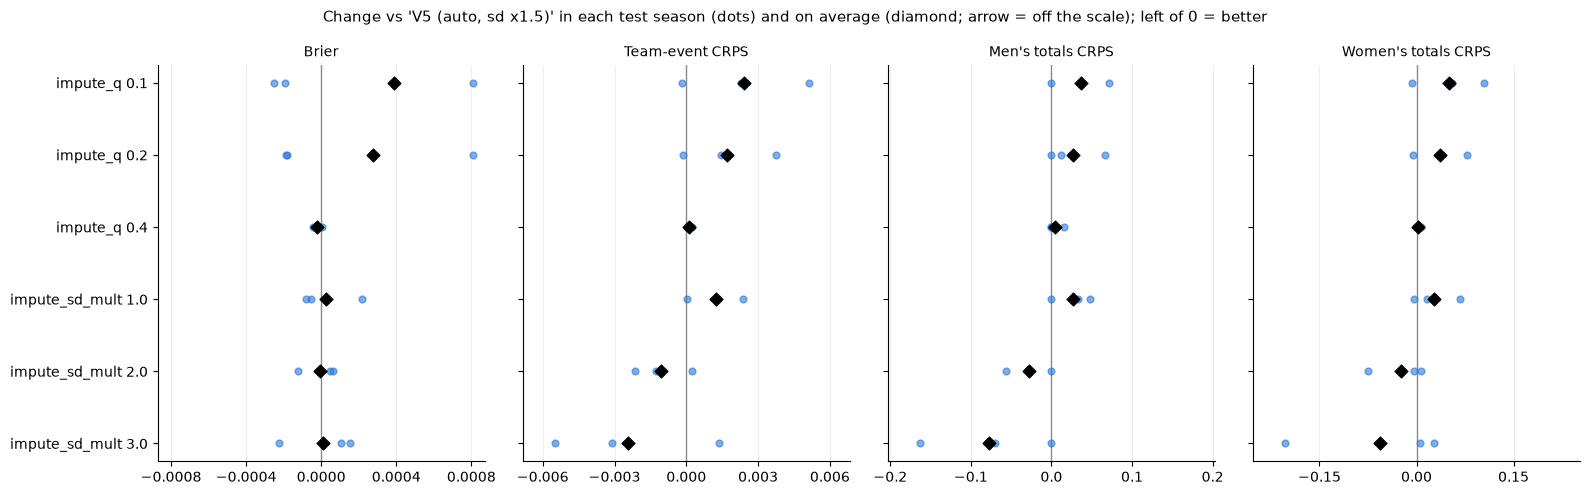

impute_q learned per fold: {2023: 0.409, 2024: 0.401, 2025: 0.421}
All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,impute_q 0.2,M_total_crps_model,6.390,6.390,True
1,impute_q 0.2,W_total_crps_model,5.563,5.563,True
2,impute_sd_mult 3.0,M_total_crps_model,6.286,6.286,True
3,impute_sd_mult 3.0,W_total_crps_model,5.470,5.470,True


In [96]:
step8f, mean8f = run_step("8f imputation", {
    "V5 (auto, sd x1.5)":     (V5, FOLDS),
    "impute_q 0.1":           ({**V5, "impute_q": 0.1}, FOLDS),
    "impute_q 0.2":           ({**V5, "impute_q": 0.2}, FOLDS),
    "impute_q 0.4":           ({**V5, "impute_q": 0.4}, FOLDS),
    "impute_sd_mult 1.0":     ({**V5, "impute_sd_mult": 1.0}, FOLDS),
    "impute_sd_mult 2.0":     ({**V5, "impute_sd_mult": 2.0}, FOLDS),
    "impute_sd_mult 3.0":     ({**V5, "impute_sd_mult": 3.0}, FOLDS),
})
print("impute_q learned per fold:", {t: round(r["ctx"]["cal"]["_pooled"]["impute_q"], 3)
                                     for t, r in results["V5 (auto, sd x1.5)"].items()})
check(mean8f, {("impute_q 0.2", "M_total_crps_model"): 6.390, ("impute_q 0.2", "W_total_crps_model"): 5.563,
               ("impute_sd_mult 3.0", "M_total_crps_model"): 6.286, ("impute_sd_mult 3.0", "W_total_crps_model"): 5.470})

**Result**
- **`impute_q`:** these entrants finished at about the 40th percentile of their field (0.41, 0.40, 0.42 per fold,
  from 40–56 athletes). Fixed values of 0.1 or 0.2 make team totals worse.
- **`impute_sd_mult`:** their results scatter by about 3 field-median spreads (robust estimate 2.8–3.1), wider than
  1.5. A multiplier of 3 improves average team totals (men 6.36 → 6.29, women 5.53 → 5.47), but only in 2/3 folds
  for men and 1/3 for women.

**Decision: keep both.** The difference is small and uneven, and found after the 2026 test.

### 8g. All data-based settings together (V8)
Four settings had data-based estimates that were each slightly better on validation: `k_spread` (~15),
`cal_prior_n` (~5), `dns_as_fail = False` and `impute_sd_mult` (~3). V8 combines them to see whether they add up.
`blowup_z = 5` and `ridge = 0.1` are not included: they were the best of a grid, not estimates from the data.

V8 is also run on 2026 as a labelled after-the-fact check. The reported model stays V5.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
V8 all data-based settings,2.331,-0.161,0.107,1.227,6.257,5.430,0.963,0.960
V5 everyone,2.318,-0.279,0.064,1.330,8.212,8.535,0.943,0.939
V8 everyone,2.322,-0.297,0.064,1.330,8.198,8.504,0.947,0.936


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V8 all data-based settings,1/3,3/3,2/3,3/3,2/3,0/3,0/3
V5 everyone,2/3,3/3,0/3,1/3,0/3,1/3,1/3
V8 everyone,1/3,3/3,0/3,1/3,0/3,2/3,1/3


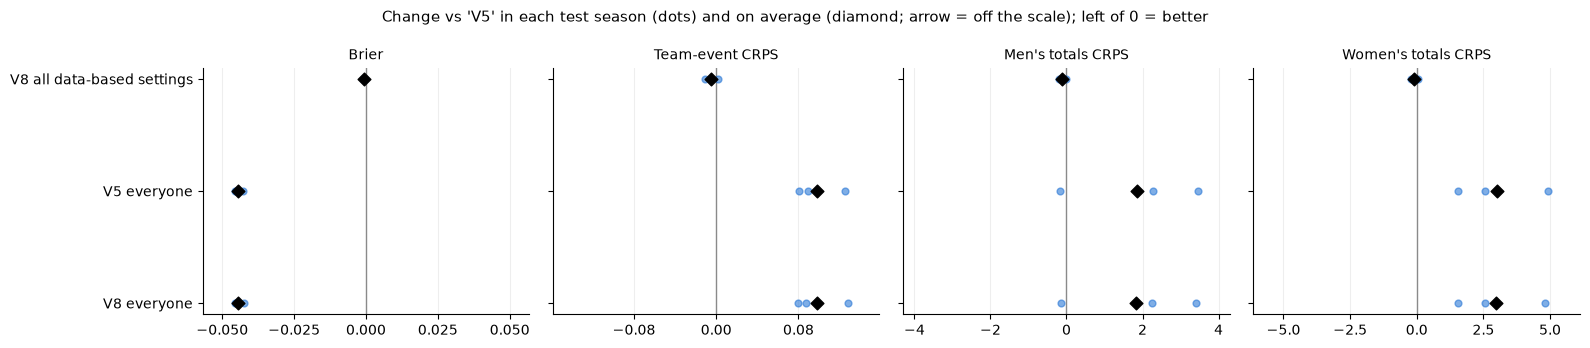

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V8 all data-based settings,M_total_crps_model,6.257,6.257,True
1,V8 all data-based settings,W_total_crps_model,5.430,5.430,True
2,V8 all data-based settings,te_crps_model,1.227,1.227,True


In [97]:
step8g, mean8g = run_step("8g data-based settings", {
    "V5":                                (V5, FOLDS),
    "V8 all data-based settings":        (V8, FOLDS),
    "V5 everyone":                       ({**V5, "field_mode": "everyone"}, FOLDS),
    "V8 everyone":                       ({**V8, "field_mode": "everyone"}, FOLDS),
})
check(mean8g, {("V8 all data-based settings", "M_total_crps_model"): 6.257,
               ("V8 all data-based settings", "W_total_crps_model"): 5.430,
               ("V8 all data-based settings", "te_crps_model"): 1.227})

In [98]:
train, test = FINAL_FOLD
post = {}
for label, settings in [("V5", V5), ("V8", V8), ("V5 everyone", {**V5, "field_mode": "everyone"}),
                        ("V8 everyone", {**V8, "field_mode": "everyone"})]:
    s = bm.run_fold(reg, bw, train, test, cdates, bw_events, {**CFG, **settings}, verbose=False)["summary"]
    post[label] = {k: s[k] for k in ["mark_mae_pct", "brier_model", "te_crps_model", "M_total_crps_model",
                                     "W_total_crps_model", "M_total_mae_model", "W_total_mae_model",
                                     "M_spearman_model", "W_spearman_model"]}
post = pd.DataFrame(post)
display(post.round(3))
assert abs(post.loc["M_total_crps_model", "V8"] - 5.737) < 0.006 and abs(post.loc["W_total_crps_model", "V8"] - 9.735) < 0.006

,V5,V8,V5 everyone,V8 everyone
mark_mae_pct,2.020,2.017,2.029,2.026
brier_model,0.112,0.111,0.063,0.063
te_crps_model,1.218,1.213,1.302,1.300
M_total_crps_model,5.750,5.737,7.584,7.571
W_total_crps_model,9.633,9.735,10.046,10.251
M_total_mae_model,8.000,8.100,10.500,10.700
W_total_mae_model,13.909,13.818,13.455,13.636
M_spearman_model,1.000,1.000,0.927,0.927
W_spearman_model,0.902,0.925,0.925,0.925


**Result on validation and 2026**
- On validation the four settings add up to a small, consistent gain: Brier better in 3/3 folds, men's totals
  6.36 → 6.26 (3/3), women's 5.53 → 5.43 (2/3), about 1.7% or 0.1 points per team total.
- On 2026 there is no consistent difference: men 5.75 → 5.74, women 9.63 → 9.74 (CRPS).

Because 2026 is a single season, V8 is also run on all seven seasons: if the gain is real it should show up in
most of them.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5 (LOSO),2.325,-0.182,0.118,1.252,6.839,7.029,0.968,0.889
V8 (LOSO),2.327,-0.165,0.118,1.249,6.771,6.956,0.968,0.896


Seasons where each version beats 'V5 (LOSO)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V8 (LOSO),1/7,6/7,5/7,5/7,5/7,0/7,2/7


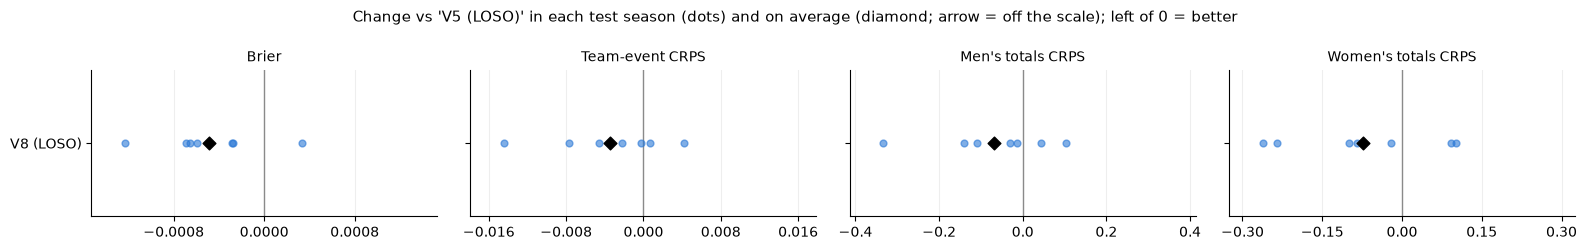

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V8 (LOSO),te_crps_model,1.249,1.249,True
1,V8 (LOSO),M_total_crps_model,6.771,6.771,True
2,V8 (LOSO),W_total_crps_model,6.956,6.956,True
3,V5 (LOSO),M_total_crps_model,6.839,6.839,True
4,V5 (LOSO),W_total_crps_model,7.029,7.029,True


In [99]:
step8g_loso, mean8g_loso = run_step("8g seven seasons", {
    "V5 (LOSO)": (V5, LOSO),
    "V8 (LOSO)": (V8, LOSO),
})
check(mean8g_loso, {
    ('V8 (LOSO)', 'te_crps_model'): 1.249,
    ('V8 (LOSO)', 'M_total_crps_model'): 6.771,
    ('V8 (LOSO)', 'W_total_crps_model'): 6.956,
    ('V5 (LOSO)', 'M_total_crps_model'): 6.839,
    ('V5 (LOSO)', 'W_total_crps_model'): 7.029,
})

**Result: V8 holds up over seven seasons.**
- V8 beats V5 in 6/7 seasons on Brier and 5/7 on team-event CRPS, men's totals (6.84 → 6.77) and women's totals
  (7.03 → 6.96). The gain is small (about 1%) but consistent.
- None of the four values were picked by comparing results: `k_spread` is estimated in each fold, `cal_prior_n = 5`
  is the empirical-Bayes estimate from 8e, and the other two come from 8e/8f measurements.

**Decision: keep V8.** V5 stays the clean 2026 holdout result (step 7).

# Part 4. Does the model genuinely learn?
## Step 9. Model checks
Four checks that the accuracy is real and not fitted to the folds used to choose the model:
- **9a.** Do the kept changes still help on the seasons never used to choose anything (2019, 2021, 2022)?
- **9b.** How much of the remaining error is plain randomness (the noise floor)?
- **9c.** Does the accuracy come from the athletes' data? (Shuffle the athlete profiles and see if it collapses.)
- **9d.** Are the scoring probabilities calibrated?

9b–9d use the final model on all seven seasons.

### 9a. Seasons never used for selection

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V1 (unseen),2.432,-0.216,0.131,1.283,7.593,7.666,0.970,0.815
V2 (unseen),2.436,-0.198,0.131,1.291,7.585,7.743,0.962,0.815
V3 (unseen),2.436,-0.198,0.131,1.282,7.519,7.644,0.962,0.831
V5 (unseen),2.436,-0.198,0.131,1.282,7.603,7.778,0.962,0.815
V8 (unseen),2.438,-0.177,0.130,1.284,7.516,7.656,0.962,0.823
V13 (unseen),2.438,-0.177,0.130,1.257,7.184,7.437,0.954,0.815


Seasons where each version beats 'V1 (unseen)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V2 (unseen),1/3,0/3,1/3,2/3,1/3,0/3,0/3
V3 (unseen),1/3,1/3,1/3,2/3,1/3,0/3,1/3
V5 (unseen),1/3,1/3,1/3,1/3,0/3,0/3,0/3
V8 (unseen),1/3,2/3,1/3,1/3,1/3,0/3,1/3
V13 (unseen),1/3,2/3,3/3,3/3,3/3,0/3,0/3


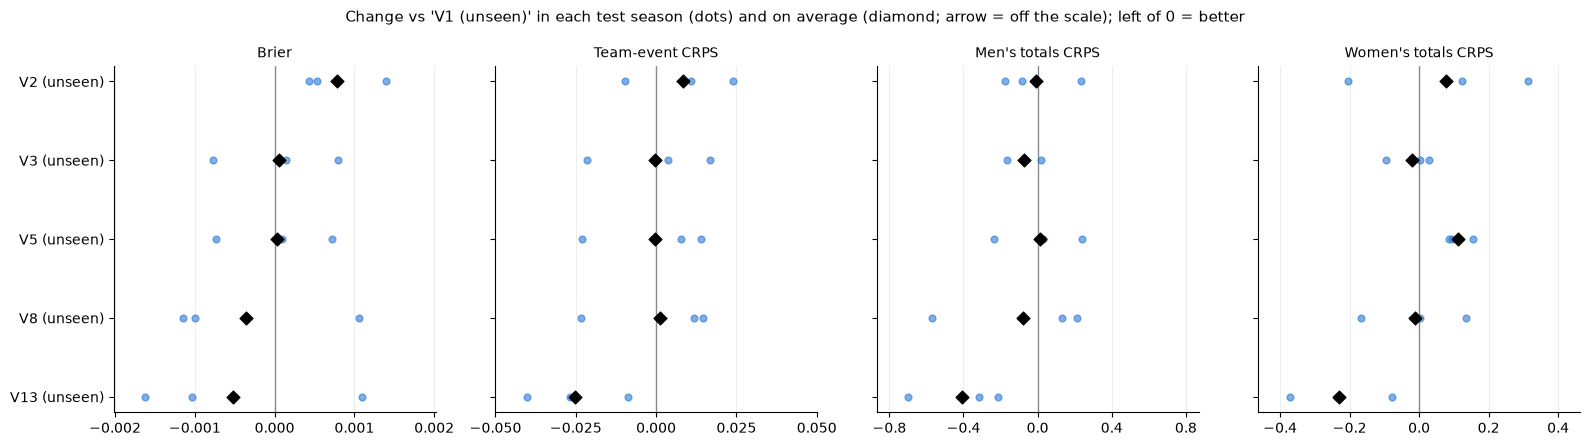

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V1 (unseen),M_total_crps_model,7.593,7.593,True
1,V1 (unseen),W_total_crps_model,7.666,7.666,True
2,V5 (unseen),M_total_crps_model,7.603,7.603,True
3,V5 (unseen),W_total_crps_model,7.778,7.778,True
4,V13 (unseen),te_crps_model,1.257,1.257,True
5,V13 (unseen),M_total_crps_model,7.184,7.184,True
6,V13 (unseen),W_total_crps_model,7.437,7.437,True


In [100]:
step9a, mean9a = run_step("9a unseen seasons", {
    "V1 (unseen)":  (V1, UNSEEN_FOLDS),
    "V2 (unseen)":  (V2, UNSEEN_FOLDS),
    "V3 (unseen)":  (V3, UNSEEN_FOLDS),
    "V5 (unseen)":  (V5, UNSEEN_FOLDS),
    "V8 (unseen)":  (V8, UNSEEN_FOLDS),
    "V13 (unseen)": (V13, UNSEEN_FOLDS),
})
check(mean9a, {
    ('V1 (unseen)', 'M_total_crps_model'): 7.593,
    ('V1 (unseen)', 'W_total_crps_model'): 7.666,
    ('V5 (unseen)', 'M_total_crps_model'): 7.603,
    ('V5 (unseen)', 'W_total_crps_model'): 7.778,
    ('V13 (unseen)', 'te_crps_model'): 1.257,
    ('V13 (unseen)', 'M_total_crps_model'): 7.184,
    ('V13 (unseen)', 'W_total_crps_model'): 7.437,
})

**Result**
- V1 → V5 alone don't show a gain on these three seasons: V5 is about level with the plain V1 (men's totals 7.60 vs
  7.59, women's 7.78 vs 7.67). Part of the V2–V5 gain on 2023–2025 was specific to those seasons.
- The final model does better: **V13 beats V1 in all three seasons** on team-event CRPS, men's totals (7.59 → 7.18)
  and women's totals (7.67 → 7.44). Most of that comes from the relay change (V8 → V13).
- Brier and mark error are flat across versions on these seasons.

**Takeaway:** the kept changes are justified by the seven-season results and by realism (prelims exist, teams run
their best relay), not by the three validation folds alone.

### 9b. Noise floor
If the model were exactly right, the real result would behave like one more draw from its own simulations. The
CRPS it would then get on average is the **noise floor**: error that no model could remove. Real CRPS close to
the floor means little is left to learn; real CRPS well above it means the model is missing something.

Team-total CRPS vs the noise floor (seven seasons):


,real,floor,gap
gender,,,
M,6.652,6.706,-0.054
W,7.046,6.473,0.573


real        floor      
gender      M      W     M     W
test                            
2019     6.95   8.19  7.92  6.56
2021     4.52   4.03  6.09  5.19
2022    10.08  10.10  6.82  6.62
2023     7.45   4.49  7.12  7.03
2024     6.28   5.58  6.43  6.51
2025     5.61   6.88  6.54  6.56
2026     5.90   9.90  6.22  6.81

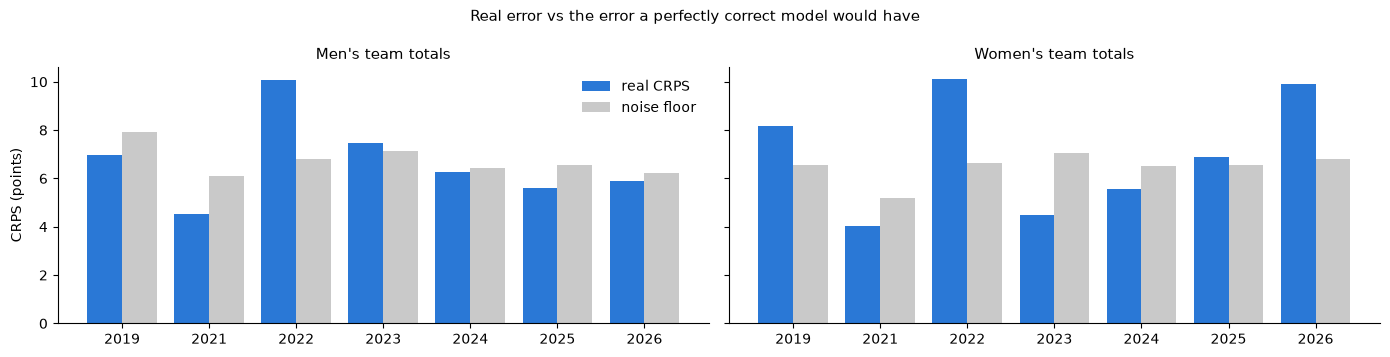

Team totals missed by 20+ points:


,test,gender,team,actual,med,miss
36,2022,M,CAL ST. FULLERTON,200.0,168.0,-32.0
16,2019,W,UC SANTA BARBARA,123.0,93.0,-30.0
55,2023,M,CAL ST. FULLERTON,184.5,155.0,-29.5
46,2022,W,HAWAII,108.0,85.0,-23.0
128,2026,W,CAL ST. FULLERTON,126.0,103.0,-23.0
85,2024,W,CAL POLY,130.8,108.0,-22.8
126,2026,W,UC IRVINE,187.5,166.0,-21.5
56,2023,M,LONG BEACH ST.,182.5,161.0,-21.5
48,2022,W,UC RIVERSIDE,63.0,42.0,-21.0
123,2026,M,CAL POLY,201.5,181.0,-20.5


In [101]:
loso_final = run_version("V13 final (LOSO)", FINAL, LOSO, "9 checks")


def noise_floor(samples, rng, k=300):
    # E[CRPS(F, y)] when y is itself drawn from F
    return np.mean([bm.crps(samples, y) for y in rng.choice(samples, size=k, replace=False)])


rng = np.random.default_rng(0)
nf_rows = []
for train, test in LOSO:
    r = bm.run_fold(reg, bw, train, test, cdates, bw_events, {**CFG, **FINAL}, verbose=False, keep_samples=True)
    for _, row in r["totals"].iterrows():
        smp = r["samples"][row["gender"]][row["team"]]
        nf_rows.append(dict(test=test, gender=row["gender"], team=row["team"], actual=row["actual"],
                            med=row["med"], real=row["crps"], floor=noise_floor(smp, rng)))
nf = pd.DataFrame(nf_rows)
nf_g = nf.groupby("gender")[["real", "floor"]].mean()
nf_g["gap"] = nf_g["real"] - nf_g["floor"]
print("Team-total CRPS vs the noise floor (seven seasons):")
display(nf_g.round(3))
nf_s = nf.groupby(["test", "gender"])[["real", "floor"]].mean().unstack("gender")
display(nf_s.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
x = np.arange(len(ALL_SEASONS))
for ax, g in zip(axes, ["M", "W"]):
    ax.bar(x - 0.2, nf_s[("real", g)], 0.4, color=BLUE, label="real CRPS")
    ax.bar(x + 0.2, nf_s[("floor", g)], 0.4, color="#c9c9c9", label="noise floor")
    ax.set_xticks(x, ALL_SEASONS)
    ax.set_title({"M": "Men", "W": "Women"}[g] + "'s team totals", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("CRPS (points)")
axes[0].legend(frameon=False)
fig.suptitle("Real error vs the error a perfectly correct model would have", fontsize=11)
fig.tight_layout(); plt.show()

nf["miss"] = nf["med"] - nf["actual"]
print("Team totals missed by 20+ points:")
display(nf[nf["miss"].abs() >= 20].sort_values("miss")[["test", "gender", "team", "actual", "med", "miss"]].round(1))

**Result**
- **Men's team totals sit at the floor** (6.65 vs 6.71): the remaining error is the kind a perfectly correct model
  would also have.
- **Women's are above it by 0.57 points**, mostly from 2019, 2022 and 2026. 2022 is above the floor for both genders.
- The large misses (table) come from whole teams having a much better or worse meet than their athletes' marks
  suggest: Fullerton's men and women in 2022, Fullerton's men in 2023, several women's teams in 2026. Step 10h
  tests whether those swings are predictable.

### 9c. Permutation test
Each athlete's profile is swapped with another entrant's in the same event, then the meet is simulated again.
If the accuracy comes from knowing the athletes, the shuffled model should be far worse.

,M_real,M_shuffled,W_real,W_shuffled,brier_real,brier_shuffled
test,,,,,,
2019,6.954,19.237,8.187,16.785,0.141,0.353
2021,4.517,11.666,4.027,15.050,0.117,0.364
2022,10.081,20.538,10.098,11.675,0.133,0.328
2023,7.446,32.996,4.493,16.729,0.108,0.362
2024,6.283,24.469,5.581,19.591,0.110,0.323
2025,5.609,29.042,6.879,25.761,0.101,0.322
2026,5.904,27.383,9.902,19.167,0.110,0.318


mean: {'M_real': 6.685, 'M_shuffled': 23.619, 'W_real': 7.024, 'W_shuffled': 17.823, 'brier_real': 0.117, 'brier_shuffled': 0.339}


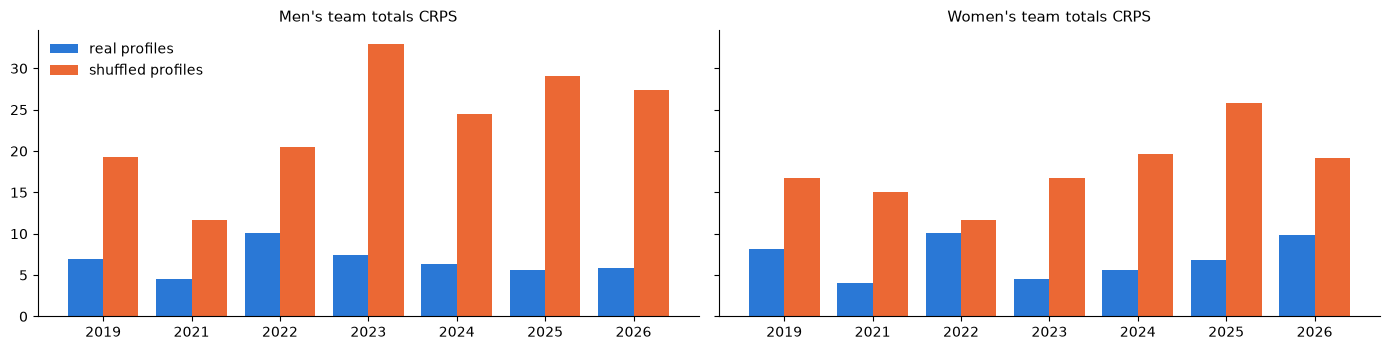

In [102]:
def shuffle_profiles(prof, rng):
    p = prof.copy()
    cols = ["mu", "sd", "best", "p_fail", "n_fail", "n_entries", "n_eff", "n_direct"]
    for _, idx in p.groupby(["gender", "event"]).groups.items():
        idx = list(idx)
        if len(idx) > 1:
            p.loc[idx, cols] = p.loc[rng.permutation(idx), cols].to_numpy()
    return p


perm = []
for train, test in LOSO:
    real = loso_final.set_index("test").loc[test]
    sh = bm.run_fold(reg, bw, train, test, cdates, bw_events, {**CFG, **FINAL}, verbose=False,
                     prof_transform=shuffle_profiles)["summary"]
    perm.append(dict(test=test, M_real=real["M_total_crps_model"], M_shuffled=sh["M_total_crps_model"],
                     W_real=real["W_total_crps_model"], W_shuffled=sh["W_total_crps_model"],
                     brier_real=real["brier_model"], brier_shuffled=sh["brier_model"]))
perm = pd.DataFrame(perm).set_index("test")
display(perm.round(3))
print("mean:", perm.mean().round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, g in zip(axes, ["M", "W"]):
    ax.bar(x - 0.2, perm[f"{g}_real"], 0.4, color=BLUE, label="real profiles")
    ax.bar(x + 0.2, perm[f"{g}_shuffled"], 0.4, color=ORANGE, label="shuffled profiles")
    ax.set_xticks(x, ALL_SEASONS)
    ax.set_title({"M": "Men", "W": "Women"}[g] + "'s team totals CRPS", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout(); plt.show()

**Result: the model's accuracy comes from the athletes' data.** With shuffled profiles, team-total CRPS goes
from 6.7 to 23.6 (men) and 7.0 to 17.8 (women), and Brier from 0.117 to 0.339, in every one of the seven seasons.

### 9d. Calibration
Athletes are grouped by the model's chance of scoring; within each group, the share who actually scored should
match the predicted chance (the dashed line).

,athletes,predicted,actual
0-10%,1275,0.031,0.037
10-20%,553,0.149,0.099
20-30%,419,0.248,0.174
30-40%,387,0.349,0.326
40-50%,371,0.450,0.447
50-60%,325,0.546,0.582
60-70%,285,0.651,0.730
70-80%,343,0.752,0.781
80-90%,508,0.854,0.880
90-100%,791,0.953,0.962


overall: predicted 0.444 of athletes would score, actual 0.445


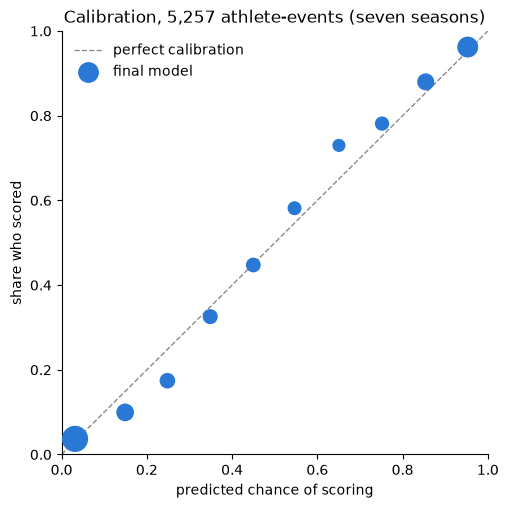

In [103]:
A = pd.concat([r["athletes"] for r in results["V13 final (LOSO)"].values()], ignore_index=True)
A["scored"] = A["actual_pts"] > 0
A["bin"] = (A["p_score"] * 10).clip(0, 9).astype(int)
calib = A.groupby("bin").agg(athletes=("scored", "size"), predicted=("p_score", "mean"), actual=("scored", "mean"))
calib.index = [f"{10*b}-{10*b+10}%" for b in calib.index]
display(calib.round(3))
print(f"overall: predicted {A['p_score'].mean():.3f} of athletes would score, actual {A['scored'].mean():.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", color=GRAY, lw=1, label="perfect calibration")
ax.scatter(calib["predicted"], calib["actual"], s=calib["athletes"] / 4, color=BLUE, zorder=3, label="final model")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="predicted chance of scoring", ylabel="share who scored",
       title=f"Calibration, {len(A):,} athlete-events (seven seasons)")
ax.legend(frameon=False, loc="upper left"); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Result**
- Overall the chances add up: 44.4% of entrants were expected to score and 44.5% did.
- Below 10% and above 80%, predicted and actual rates are within about 3 points.
- In between the model is a little too cautious: athletes given 10–30% scored 10–17% of the time, and athletes
  given 50–70% scored 58–73% of the time. Outsiders are rated slightly too high and likely scorers slightly too low.

# Part 5. Other ideas tested
## Step 10. Changes that were not kept
Each idea is compared with V5 (the model at the time it was tested) on the validation folds. The spread
(10g) and team effect (10h) ideas are also run on seven seasons.

### 10a. Separate slopes for men in the regressions
Both regressions (offset and failure chance) get their own men's slopes for `sb_level`, `gap`, `risk` and
`log_starts`, so women's and men's athletes can respond differently (a "women-specific model" without splitting
the data in half).

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
10a men's own slopes,2.330,-0.158,0.108,1.233,6.337,5.541,0.963,0.96


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10a men's own slopes,1/3,3/3,1/3,1/3,0/3,0/3,0/3


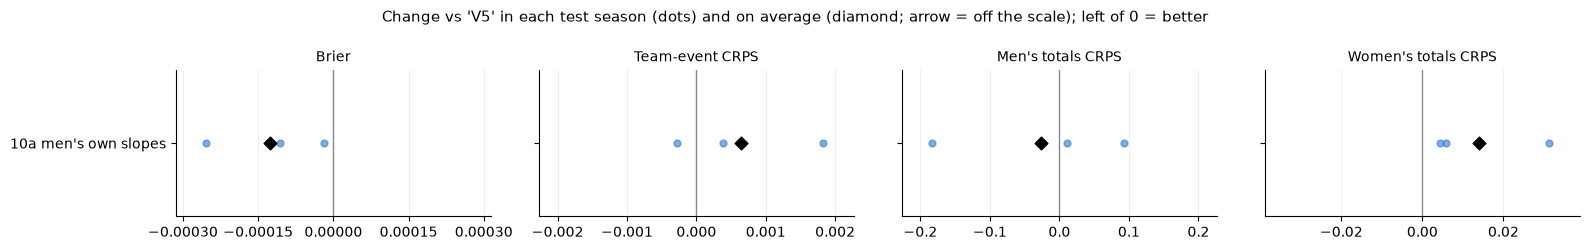

Offset model, % of the mark (women's slope = base; men's = base + men_x_):


,2023,2024,2025
sb_level,-0.194,-0.185,-0.254
gap,0.272,0.255,0.327
risk,-0.016,0.012,0.112
log_starts,-0.315,-0.205,-0.257
men_x_sb_level,0.031,0.077,0.072
men_x_gap,0.058,0.046,-0.052
men_x_risk,-0.069,0.134,0.044
men_x_log_starts,-0.045,0.013,0.168


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,10a men's own slopes,M_total_crps_model,6.337,6.337,True
1,10a men's own slopes,W_total_crps_model,5.541,5.541,True


In [104]:
step10a, mean10a = run_step("10a gender slopes", {
    "V5": (V5, FOLDS),
    "10a men's own slopes": ({**V5, "gender_interactions": True}, FOLDS),
})
print("Offset model, % of the mark (women's slope = base; men's = base + men_x_):")
display(coef_table("10a men's own slopes", "offset_beta", 100).loc[["sb_level", "gap", "risk", "log_starts",
        "men_x_sb_level", "men_x_gap", "men_x_risk", "men_x_log_starts"]])
check(mean10a, {
    ("10a men's own slopes", 'M_total_crps_model'): 6.337,
    ("10a men's own slopes", 'W_total_crps_model'): 5.541,
})

**Result: not kept.** The men's slopes are small and change sign between folds (e.g. `men_x_gap` +0.06,
+0.05, −0.05). Brier is better in 3/3 folds, but team totals are not (men 1/3, women 0/3). The shared slopes
already fit both genders.

### 10b. Recency as a function
Two ways of letting recency depend on the athlete instead of one fixed half-life:
- **Half-life per event group:** estimated from the training seasons for sprints, distance, jumps, throws and multis.
- **Recent form:** a regression feature, the average of the athlete's last two marks minus their weighted mean
  (positive = trending up). The regression decides how much it matters.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
10b half-life per event group,2.329,-0.150,0.108,1.236,6.549,5.556,0.963,0.964
10b recent-form feature,2.328,-0.152,0.108,1.234,6.394,5.511,0.963,0.960


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10b half-life per event group,1/3,1/3,0/3,1/3,1/3,0/3,1/3
10b recent-form feature,2/3,2/3,1/3,1/3,2/3,0/3,0/3


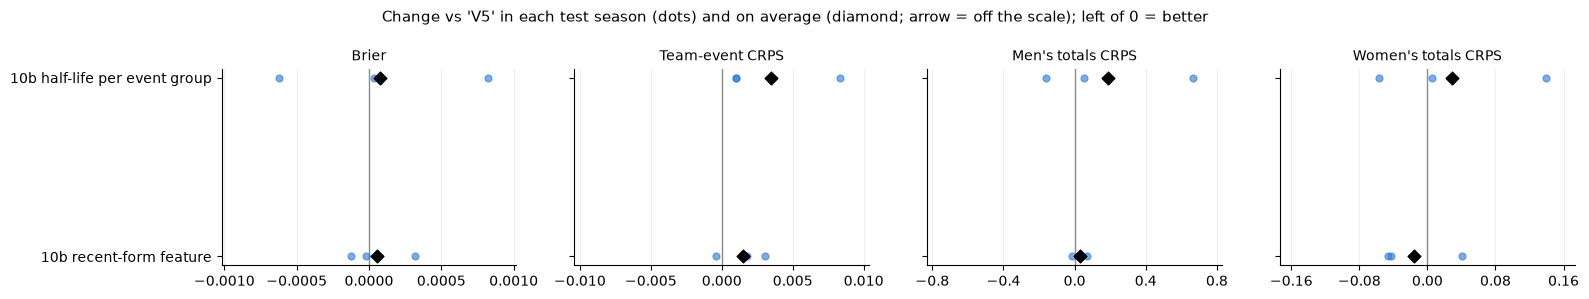

Half-life estimated per event group (days):


,2023,2024,2025
_all,19.3,20.7,20.8
sprint,20.8,19.2,19.8
distance,67.2,39.4,39.4
horizontal,28.9,26.6,33.5
vertical,35.3,48.5,44.5
throw,17.8,19.3,20.8
multi,18.8,18.8,18.8


Recent-form coefficient (% of the mark per 1% of recent form):


,2023,2024,2025
recent_form,0.054,0.044,0.049


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,10b half-life per event group,M_total_crps_model,6.549,6.549,True
1,10b half-life per event group,W_total_crps_model,5.556,5.556,True
2,10b recent-form feature,M_total_crps_model,6.394,6.394,True
3,10b recent-form feature,W_total_crps_model,5.511,5.511,True


In [105]:
step10b, mean10b = run_step("10b recency", {
    "V5": (V5, FOLDS),
    "10b half-life per event group": ({**V5, "half_life_days": "auto_group"}, FOLDS),
    "10b recent-form feature": ({**V5, "recent_form": True}, FOLDS),
})
print("Half-life estimated per event group (days):")
display(pd.DataFrame({t: r["ctx"]["cfg"]["half_life_days"] for t, r in results["10b half-life per event group"].items()}).round(1))
print("Recent-form coefficient (% of the mark per 1% of recent form):")
display(coef_table("10b recent-form feature", "offset_beta", 100).loc[["recent_form"]])
check(mean10b, {
    ('10b half-life per event group', 'M_total_crps_model'): 6.549,
    ('10b half-life per event group', 'W_total_crps_model'): 5.556,
    ('10b recent-form feature', 'M_total_crps_model'): 6.394,
    ('10b recent-form feature', 'W_total_crps_model'): 5.511,
})

**Result: not kept.**
- **Half-life per event group:** the data does give different half-lives (sprints and throws about 20 days,
  jumps 27–49, distance 39–67), but team totals get worse (men 6.36 → 6.55, women 5.53 → 5.56).
- **Recent form:** the regression gives it a small weight (0.04–0.05% per 1% of form). Women's totals are better in
  2/3 folds (5.53 → 5.51) but men's in only 1/3 (6.36 → 6.39); team-event CRPS is better in 1/3.
- A single 45-day half-life with the `gap` feature already captures most of what recency adds.

### 10c. Heavy-tailed (Student-t) noise
The model draws each athlete's day from a normal distribution. The residuals from 8e show how close that is:

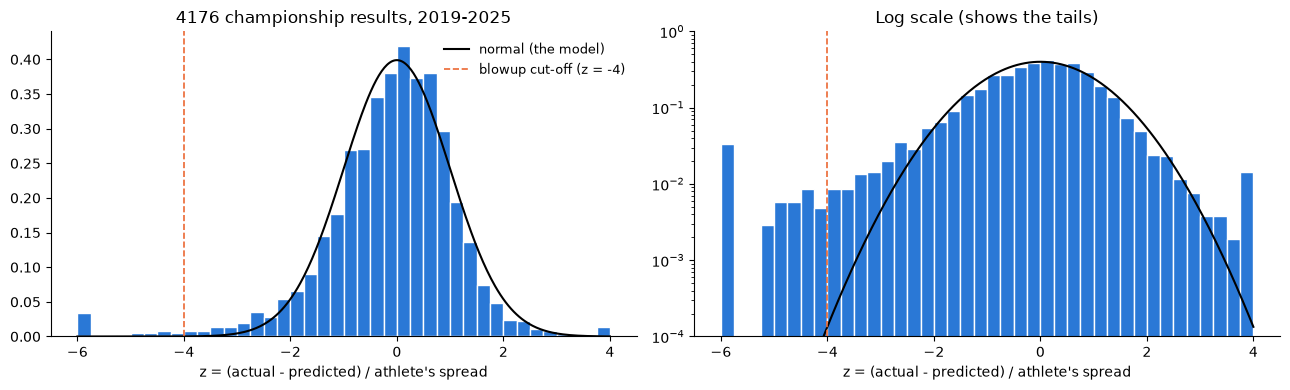

within +-1: 68.4% (normal: 68.3%) | below -3: 2.7% | above +3: 0.6% (normal: 0.13% each)


In [106]:
from scipy.stats import norm, t as student_t
zz = resid["z"].dropna()
xs = np.linspace(-6, 4, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, log in zip(axes, [False, True]):
    ax.hist(zz.clip(-6, 4), bins=np.arange(-6, 4.25, 0.25), density=True, color=BLUE, edgecolor="white")
    ax.plot(xs, norm.pdf(xs), color="black", lw=1.5, label="normal (the model)")
    ax.axvline(-CFG["blowup_z"], color=ORANGE, ls="--", lw=1.2, label=f"blowup cut-off (z = -{CFG['blowup_z']:g})")
    ax.set_xlabel("z = (actual - predicted) / athlete's spread")
    ax.spines[["top", "right"]].set_visible(False)
    if log:
        ax.set_yscale("log"); ax.set_ylim(1e-4, 1); ax.set_title("Log scale (shows the tails)")
    else:
        ax.set_title(f"{len(zz)} championship results, 2019-2025"); ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()
print(f"within +-1: {(zz.abs() <= 1).mean():.1%} (normal: 68.3%) | below -3: {(zz < -3).mean():.1%} | "
      f"above +3: {(zz > 3).mean():.1%} (normal: 0.13% each)")

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
"10c Student-t, df from the data",2.329,-0.156,0.109,1.240,6.619,5.625,0.963,0.96


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
"10c Student-t, df from the data",0/3,0/3,0/3,0/3,1/3,0/3,0/3


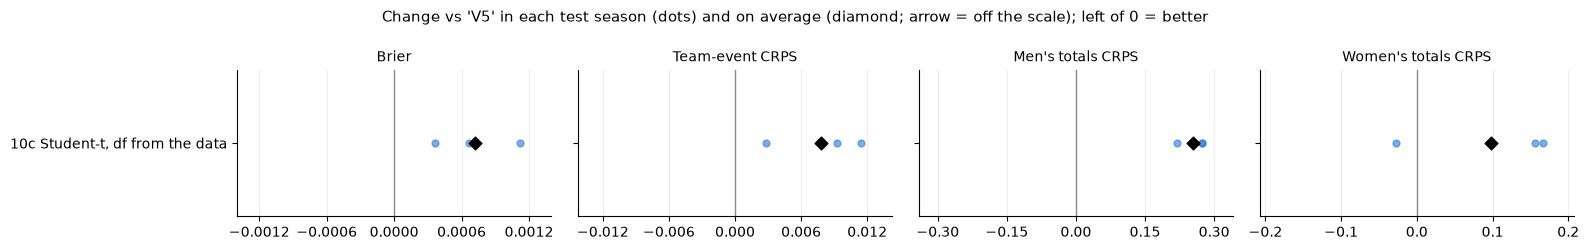

degrees of freedom estimated per fold: {2023: 6.6, 2024: 6.3, 2025: 6.1}
All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,"10c Student-t, df from the data",M_total_crps_model,6.619,6.619,True
1,"10c Student-t, df from the data",W_total_crps_model,5.625,5.625,True


In [107]:
step10c, mean10c = run_step("10c Student-t noise", {
    "V5": (V5, FOLDS),
    "10c Student-t, df from the data": ({**V5, "noise_df": "auto"}, FOLDS),
})
print("degrees of freedom estimated per fold:",
      {t: round(r["ctx"]["cal"]["_pooled"]["noise_df"], 1) for t, r in results["10c Student-t, df from the data"].items()})
check(mean10c, {
    ('10c Student-t, df from the data', 'M_total_crps_model'): 6.619,
    ('10c Student-t, df from the data', 'W_total_crps_model'): 5.625,
})

**Result: not kept.**
- The normal shape fits the middle well (68.4% of results within ±1, 68.3% expected). The extra tail is on the
  **slow side** (2.7% below −3, against 0.6% above +3), and results past −4 are already treated as failures.
- A Student-t fitted to the residuals (about 6 degrees of freedom) adds heavy tails on **both** sides, including
  big improvements that rarely happen. It is worse in 3/3 folds on Brier, team-event CRPS and men's totals.

### 10d. Weighted median instead of weighted mean
The median is robust to one bad race, so it could be a better centre than the recency-weighted mean.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
10d weighted median,2.383,-0.141,0.110,1.258,7.054,5.770,0.963,0.958


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10d weighted median,0/3,0/3,0/3,0/3,1/3,0/3,1/3


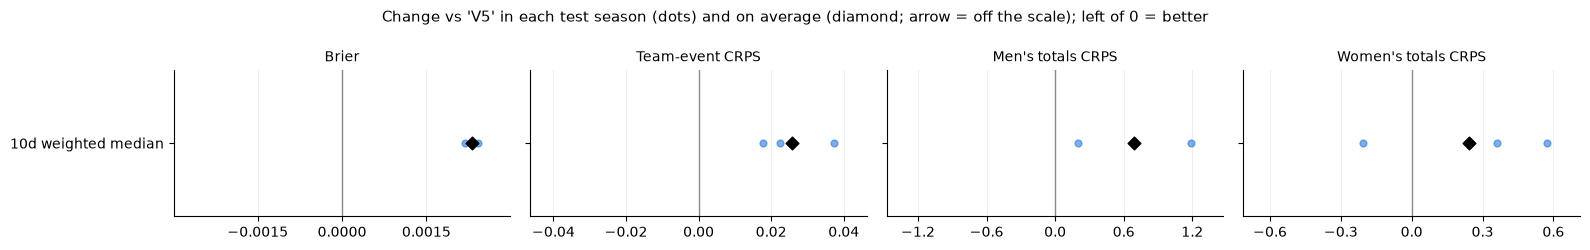

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,10d weighted median,mark_mae_pct,2.383,2.383,True
1,10d weighted median,M_total_crps_model,7.054,7.054,True
2,10d weighted median,W_total_crps_model,5.770,5.770,True


In [108]:
step10d, mean10d = run_step("10d weighted median", {
    "V5": (V5, FOLDS),
    "10d weighted median": ({**V5, "mu_method": "median"}, FOLDS),
})
check(mean10d, {
    ('10d weighted median', 'mark_mae_pct'): 2.383,
    ('10d weighted median', 'M_total_crps_model'): 7.054,
    ('10d weighted median', 'W_total_crps_model'): 5.77,
})

**Result: not kept.** The weighted median is worse on every measure: mark error 2.33% → 2.38% and men's
totals 6.36 → 7.05 (0/3 folds). With 4–6 marks per athlete, the median throws away information that the mean
uses, and bad races are already handled by flagging regular-season blowups.

### 10e. Scoring details
Three changes that make the simulation closer to real scoring:
- **Bar heights (HJ/PV):** simulated marks are rounded down to bar heights (median step at Big West: about 5 cm in
  HJ, 15 cm in PV); athletes on the same height share points as often as they did at Big West.
- **Blowups ranked last:** a finalist who fails badly still finishes and scores by place; only no-marks, DNF, DQ
  and DNS score 0.
- **Minimum spread for the multis,** pooled from the training seasons.

Their effect is small, so the step also measures how much the results move from **random draws alone**: V5
rerun with three other seeds.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
10e bar heights,2.329,-0.156,0.108,1.232,6.357,5.509,0.963,0.96
10e blowups ranked last,2.329,-0.156,0.108,1.231,6.351,5.505,0.963,0.96
10e multi spread floor,2.329,-0.155,0.108,1.232,6.372,5.523,0.963,0.96
10e all three,2.329,-0.155,0.108,1.232,6.362,5.526,0.963,0.96


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10e bar heights,0/3,2/3,1/3,2/3,2/3,0/3,0/3
10e blowups ranked last,0/3,1/3,2/3,3/3,2/3,0/3,0/3
10e multi spread floor,1/3,1/3,2/3,1/3,2/3,0/3,0/3
10e all three,1/3,2/3,3/3,2/3,2/3,0/3,0/3


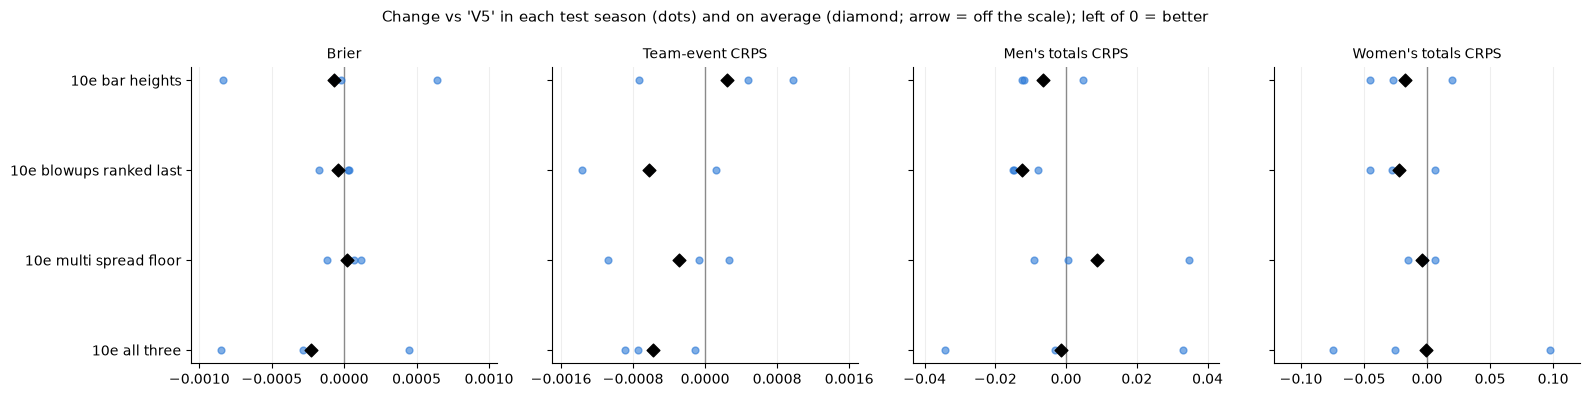

Change vs V5 (CRPS):


,te_crps_model,M_total_crps_model,W_total_crps_model
version,,,
10e bar heights,0.000,-0.007,-0.018
10e blowups ranked last,-0.001,-0.012,-0.022
10e multi spread floor,-0.000,0.009,-0.004
10e all three,-0.001,-0.001,-0.001


Random-draw noise: sd of the 3-fold mean across four seeds:


,te_crps_model,M_total_crps_model,W_total_crps_model
sd,0.0,0.004,0.007


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,10e bar heights,M_total_crps_model,6.357,6.357,True
1,10e bar heights,W_total_crps_model,5.509,5.509,True
2,10e blowups ranked last,M_total_crps_model,6.351,6.351,True
3,10e blowups ranked last,W_total_crps_model,5.505,5.505,True
4,10e multi spread floor,M_total_crps_model,6.372,6.372,True
5,10e all three,W_total_crps_model,5.526,5.526,True


In [109]:
step10e, mean10e = run_step("10e scoring details", {
    "V5": (V5, FOLDS),
    "10e bar heights": ({**V5, "bar_ties": True}, FOLDS),
    "10e blowups ranked last": ({**V5, "fail_ranked": True}, FOLDS),
    "10e multi spread floor": ({**V5, "multi_sd_floor": "auto"}, FOLDS),
    "10e all three": ({**V5, "bar_ties": True, "fail_ranked": True, "multi_sd_floor": "auto"}, FOLDS),
})
seeds = pd.concat([run_version(f"V5 seed {s}", {**V5, "seed": s}, FOLDS, "10e seed noise") for s in [1, 2, 3]]
                  + [step10e[step10e["version"] == "V5"].assign(version="V5 seed 0")])
seed_means = seeds.groupby("version")[COLS].mean()
noise = seed_means.std()[["te_crps_model", "M_total_crps_model", "W_total_crps_model"]]
change = (mean10e - mean10e.loc["V5"])[["te_crps_model", "M_total_crps_model", "W_total_crps_model"]].drop("V5")
print("Change vs V5 (CRPS):"); display(change.round(3))
print("Random-draw noise: sd of the 3-fold mean across four seeds:"); display(noise.round(3).to_frame("sd").T)
check(mean10e, {
    ('10e bar heights', 'M_total_crps_model'): 6.357,
    ('10e bar heights', 'W_total_crps_model'): 5.509,
    ('10e blowups ranked last', 'M_total_crps_model'): 6.351,
    ('10e blowups ranked last', 'W_total_crps_model'): 5.505,
    ('10e multi spread floor', 'M_total_crps_model'): 6.372,
    ('10e all three', 'W_total_crps_model'): 5.526,
})

**Result**
- All three changes are small. Random draws alone move the 3-fold mean by about 0.004 (men) and 0.007 (women).
- **Blowups ranked last** is the clearest: men's totals better in 3/3 folds and women's in 2/3 (6.364 → 6.351,
  5.527 → 5.505). That is about three times the random-draw noise, but only 0.01–0.02 points per team total.
- **Bar heights** improves totals in 2/3 folds by a similar small amount. **Multi spread floor** is mixed.
  All three together cancel out (6.362 / 5.526).

**Decision: not adopted.** Blowups ranked last technically passes the keep rule, but the gain is about 0.3% of
the error. It remains a reasonable candidate if the model is revisited.

### 10f. Multis centred on their season best
Some heptathletes and decathletes are badly under-predicted because their only multi of the season was a weak one.
This centres every multi athlete on their season best instead of their weighted mean.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.96
10f multis: season best,2.339,-0.149,0.108,1.232,6.362,5.546,0.963,0.96


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10f multis: season best,0/3,0/3,2/3,2/3,1/3,0/3,0/3


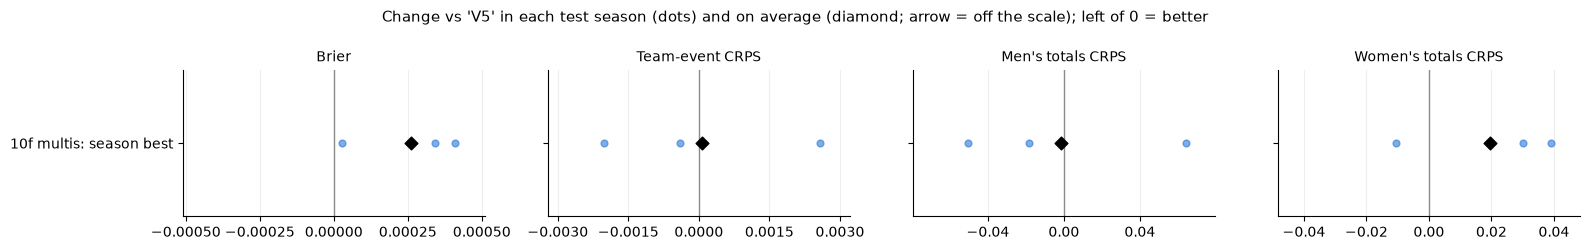

,,athletes,brier,points MAE
,group,,,
V5,multi,75.0,0.116,1.437
10f multis: season best,multi,75.0,0.124,1.482


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,10f multis: season best,mark_mae_pct,2.339,2.339,True
1,10f multis: season best,W_total_crps_model,5.546,5.546,True


In [110]:
step10f, mean10f = run_step("10f multis season best", {
    "V5": (V5, FOLDS),
    "10f multis: season best": ({**V5, "multi_mu": "best"}, FOLDS),
})
display(pd.concat({k: by_group(k).loc[["multi"]] for k in ["V5", "10f multis: season best"]}))
check(mean10f, {
    ('10f multis: season best', 'mark_mae_pct'): 2.339,
    ('10f multis: season best', 'W_total_crps_model'): 5.546,
})

**Result: not kept.** Mark error is worse (2.33% → 2.34%) and the multis' own Brier and points error get
worse (0.116 → 0.124). Most multi athletes have only one score in the season, so the season best equals the mean;
for the rest, the best is an optimistic centre.

### 10g. How the spread is measured
- **Within each race:** part of the championship spread is shared by everyone in a race (wind, heat, a slow
  tactical pace). It moves marks but not places, so it is removed from the spread used for ranking.
- **Around the athlete-specific offset:** the spread scale is measured around the event offset, but the
  simulation centres athletes on their athlete-specific offset; this re-measures the scale around that centre.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
10g spread within race,2.329,-0.156,0.107,1.230,6.257,5.569,0.957,0.952
10g spread around athlete offset,2.329,-0.156,0.108,1.234,6.399,5.503,0.963,0.960


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10g spread within race,0/3,3/3,2/3,1/3,1/3,0/3,0/3
10g spread around athlete offset,0/3,2/3,1/3,2/3,2/3,0/3,0/3


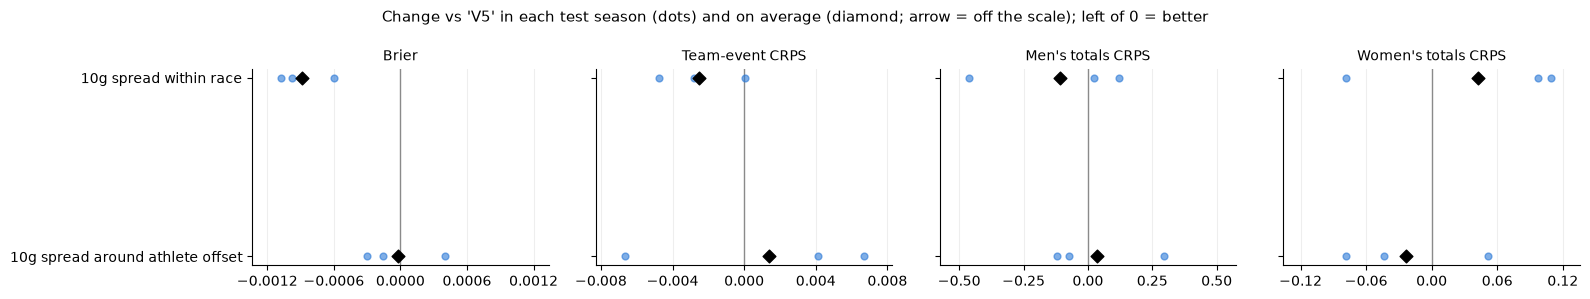

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5 (LOSO),2.325,-0.182,0.118,1.252,6.839,7.029,0.968,0.889
10g spread within race (LOSO),2.325,-0.182,0.117,1.244,6.773,7.051,0.968,0.893
10g spread around athlete offset (LOSO),2.325,-0.182,0.118,1.250,6.833,6.999,0.968,0.893


Seasons where each version beats 'V5 (LOSO)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10g spread within race (LOSO),0/7,7/7,6/7,4/7,3/7,0/7,1/7
10g spread around athlete offset (LOSO),0/7,4/7,5/7,4/7,5/7,0/7,1/7


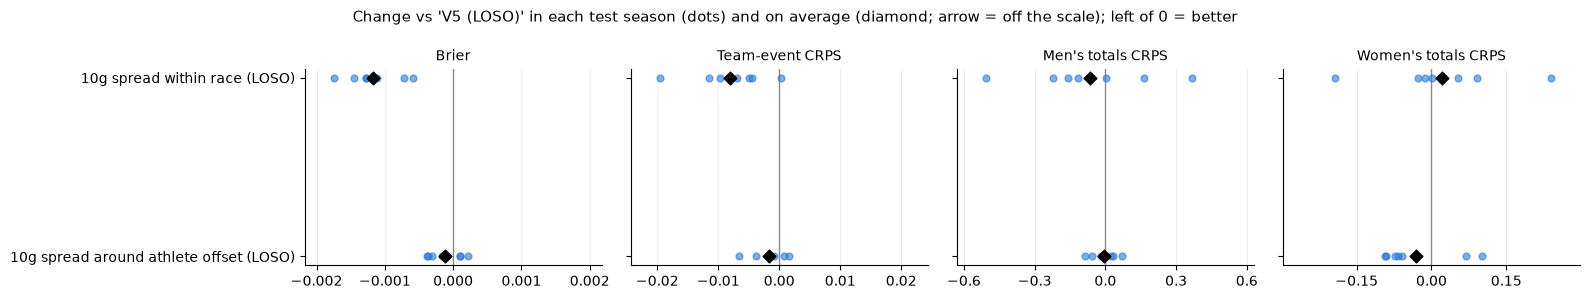

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,10g spread within race,brier_model,0.107,0.107,True
1,10g spread within race,M_total_crps_model,6.257,6.257,True
2,10g spread within race,W_total_crps_model,5.569,5.569,True
3,10g spread around athlete offset,M_total_crps_model,6.399,6.399,True
4,10g spread around athlete offset,W_total_crps_model,5.503,5.503,True


In [111]:
step10g, mean10g = run_step("10g spread", {
    "V5": (V5, FOLDS),
    "10g spread within race": ({**V5, "scale_within_race": True}, FOLDS),
    "10g spread around athlete offset": ({**V5, "scale_after_offset": True}, FOLDS),
})
step10g_loso, mean10g_loso = run_step("10g spread (LOSO)", {
    "V5 (LOSO)": (V5, LOSO),
    "10g spread within race (LOSO)": ({**V5, "scale_within_race": True}, LOSO),
    "10g spread around athlete offset (LOSO)": ({**V5, "scale_after_offset": True}, LOSO),
})
check(mean10g, {
    ('10g spread within race', 'brier_model'): 0.107,
    ('10g spread within race', 'M_total_crps_model'): 6.257,
    ('10g spread within race', 'W_total_crps_model'): 5.569,
    ('10g spread around athlete offset', 'M_total_crps_model'): 6.399,
    ('10g spread around athlete offset', 'W_total_crps_model'): 5.503,
})

**Result: not kept.**
- **Within each race:** the most consistent gain on individual athletes (Brier better in 3/3 folds and 7/7 seasons;
  team-event CRPS 6/7 seasons), but team totals are mixed (men 4/7, women 3/7 seasons).
- **Around the athlete-specific offset:** small and mixed on validation (men's average worse, 6.36 → 6.40); over
  seven seasons slightly better (women 7.03 → 7.00, 5/7). The closest call in this step, but the gain is tiny.
- Neither changes team totals reliably, which is what the keep rule asks for.

### 10h. Persistent team effect
Some programs might beat (or miss) their athletes' predictions year after year. The heat map shows each team's
average result relative to its athletes' predictions, after removing each race's shared conditions (blue = better
than predicted). A team effect is only useful if it repeats from one season to the next.

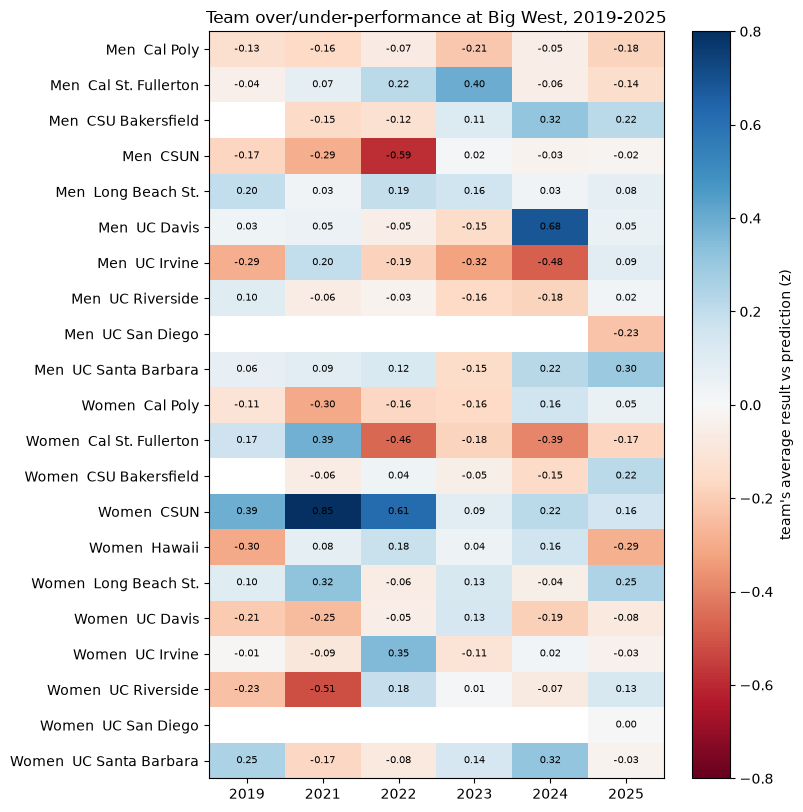

year-to-year correlation of the team effect: 0.31 (93 pairs)


In [112]:
rt = resid.merge(bw[["season", "gender", "event", "athlete_id", "team"]].drop_duplicates(bm.KEYS + ["season"]),
                 on=["season"] + bm.KEYS)
rt = rt[(rt["z"] > -4) & ~rt["event"].isin(bm.RELAYS)]
rt["zc"] = rt["z"] - rt.groupby(["season", "gender", "event"])["z"].transform("mean")
team_season = rt.groupby(["gender", "team", "season"]).agg(z=("zc", "mean"), n=("zc", "size")).reset_index()
team_season = team_season[team_season["n"] >= 10]
heat = team_season.pivot_table(index=["gender", "team"], columns="season", values="z")
fig, ax = plt.subplots(figsize=(8, 0.32 * len(heat) + 1.5))
im = ax.imshow(heat.to_numpy(), cmap="RdBu", vmin=-0.8, vmax=0.8, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
nice = lambda t: t.title().replace("Uc ", "UC ").replace("Csun", "CSUN").replace("Csu ", "CSU ")
ax.set_yticks(range(heat.shape[0]), [f"{'Men' if g == 'M' else 'Women'}  {nice(t)}" for g, t in heat.index])
for (i, j), v in np.ndenumerate(heat.to_numpy()):
    if np.isfinite(v):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="team's average result vs prediction (z)")
ax.set_title("Team over/under-performance at Big West, 2019-2025")
fig.tight_layout(); plt.show()

prev = team_season.assign(season=team_season["season"].map({2019: 2021, 2021: 2022, 2022: 2023, 2023: 2024, 2024: 2025}))
pairs = team_season.merge(prev, on=["gender", "team", "season"], suffixes=("", "_prev"))
print(f"year-to-year correlation of the team effect: {pairs['z'].corr(pairs['z_prev']):.2f} ({len(pairs)} pairs)")

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
10h persistent team effect,2.328,-0.157,0.108,1.228,6.364,5.355,0.963,0.955


Seasons where each version beats 'V5' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10h persistent team effect,2/3,3/3,3/3,0/3,3/3,0/3,1/3


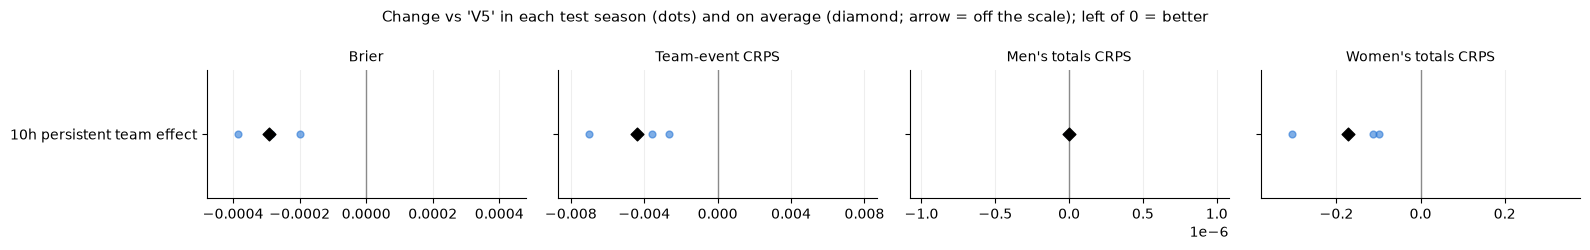

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V5 (LOSO),2.325,-0.182,0.118,1.252,6.839,7.029,0.968,0.889
10h persistent team effect (LOSO),2.326,-0.178,0.118,1.251,6.839,7.086,0.968,0.898


Seasons where each version beats 'V5 (LOSO)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
10h persistent team effect (LOSO),3/7,4/7,4/7,0/7,4/7,0/7,3/7


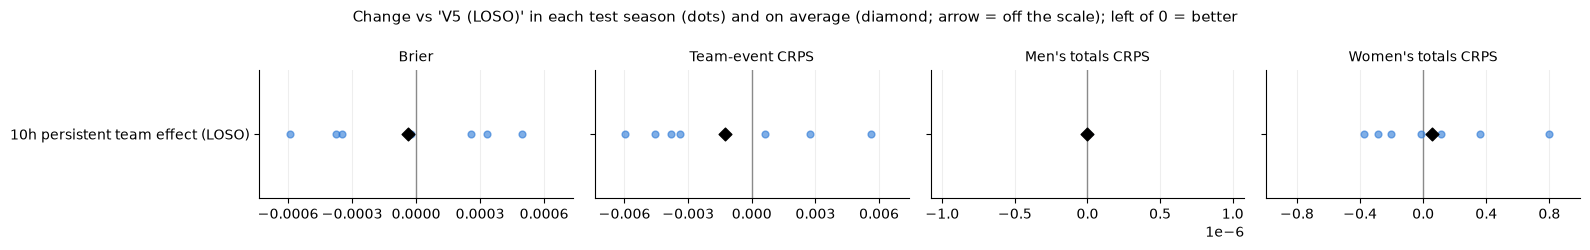

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,10h persistent team effect,te_crps_model,1.228,1.228,True
1,10h persistent team effect,W_total_crps_model,5.355,5.355,True


In [113]:
step10h, mean10h = run_step("10h team effect", {
    "V5": (V5, FOLDS),
    "10h persistent team effect": ({**V5, "team_offset": True}, FOLDS),
})
step10h_loso, mean10h_loso = run_step("10h team effect (LOSO)", {
    "V5 (LOSO)": (V5, LOSO),
    "10h persistent team effect (LOSO)": ({**V5, "team_offset": True}, LOSO),
})
check(mean10h, {
    ('10h persistent team effect', 'te_crps_model'): 1.228,
    ('10h persistent team effect', 'W_total_crps_model'): 5.355,
})

**Result**
- The team effect does repeat a little from season to season (correlation 0.31 for the same team in consecutive
  seasons), and for men it is too small to estimate (no change).
- **On the validation folds, it helps women:** totals 5.53 → 5.36 in 3/3 folds, with Brier and team-event CRPS
  better in 3/3.
- **Over seven seasons it does not:** women's totals 7.03 → 7.09, better in only 4/7. The swings that matter most
  reverse: Fullerton's women were well above prediction in 2021 and well below in 2022.

**Decision: not kept.** It passes on three seasons but not on seven. With more seasons it may become estimable.

# Part 6. Relays
## Step 11. Predicting relays
### 11a. Where the model trails the performance list
Points error per team per event by event type, model (V8) vs the performance list, over seven seasons.

,model,performance list,seasons model better
group,,,
relay,1.98,1.76,2
throw,1.59,1.78,5
sprint,1.59,2.07,7
horizontal,1.99,2.41,7
vertical,1.79,2.43,7
distance,1.67,2.52,7
multi,2.27,3.31,5


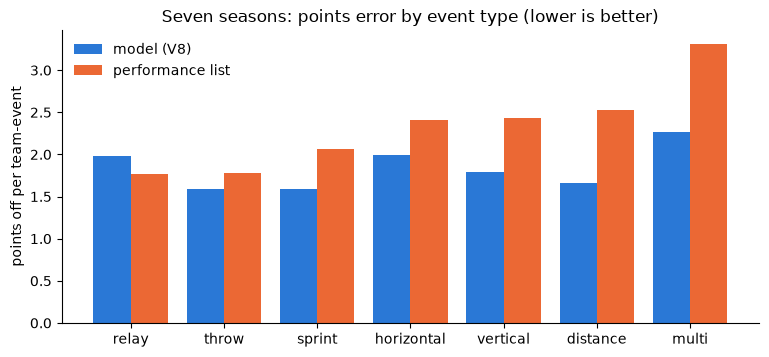

In [114]:
TE = pd.concat(r["team_event"].assign(test=t) for t, r in results["V8 (LOSO)"].items())
TE["group"] = TE["event"].map(bm.event_group)
TE["model"] = (TE["med"] - TE["actual"]).abs()
TE["performance list"] = (TE["plist_pts"] - TE["actual"]).abs()
by = TE.groupby(["group", "test"])[["model", "performance list"]].mean()
eg = TE.groupby("group")[["model", "performance list"]].mean().sort_values("performance list")
eg["seasons model better"] = (by["model"] < by["performance list"]).groupby("group").sum().reindex(eg.index)
display(eg.round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
xg = np.arange(len(eg))
ax.bar(xg - 0.2, eg["model"], 0.4, color=BLUE, label="model (V8)")
ax.bar(xg + 0.2, eg["performance list"], 0.4, color=ORANGE, label="performance list")
ax.set_xticks(xg, eg.index)
ax.set(ylabel="points off per team-event", title="Seven seasons: points error by event type (lower is better)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Result:** the model is better than the performance list in most or all seasons for every event type except
**relays**, where the list wins in 5 of 7 seasons (1.98 vs 1.76 points off per team per relay).

### 11b. Ways to predict a relay
- **Relay's own races (V8):** recency-weighted average of the relay's times this season.
- **Four best open runners:** the sum of the team's four best typical 100 / 400 times, scaled to a relay with
  the ratio measured that season (flying starts make relays faster than the sum).
- **Season best:** teams run their strongest four at Big West, while early-season relays often use other lineups.
- **Season best + four runners:** the average of the two.
- **Predicted Big West legs:** the four runners' predicted *championship* times (their level plus their
  athlete-specific Big West shift), alone or averaged with the season best. The past seasons' relays are rebuilt
  the same way so the relay calibration is learned on like-for-like predictions.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V8 (LOSO),2.327,-0.165,0.118,1.249,6.771,6.956,0.968,0.896
11b four best open runners,2.327,-0.165,0.118,1.245,6.694,7.430,0.962,0.883
11b relay season best (= V13),2.327,-0.165,0.117,1.223,6.685,7.024,0.967,0.891
11b season best + four runners,2.327,-0.165,0.117,1.232,6.667,7.205,0.962,0.889
11b predicted Big West legs,2.327,-0.165,0.118,1.247,6.724,7.413,0.966,0.879
11b season best + predicted legs,2.327,-0.165,0.117,1.233,6.677,7.205,0.962,0.889


Seasons where each version beats 'V8 (LOSO)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
11b four best open runners,0/7,2/7,4/7,4/7,1/7,0/7,1/7
11b relay season best (= V13),0/7,5/7,7/7,4/7,3/7,1/7,1/7
11b season best + four runners,0/7,4/7,5/7,4/7,1/7,0/7,1/7
11b predicted Big West legs,0/7,1/7,4/7,4/7,1/7,1/7,1/7
11b season best + predicted legs,0/7,4/7,5/7,4/7,1/7,0/7,1/7


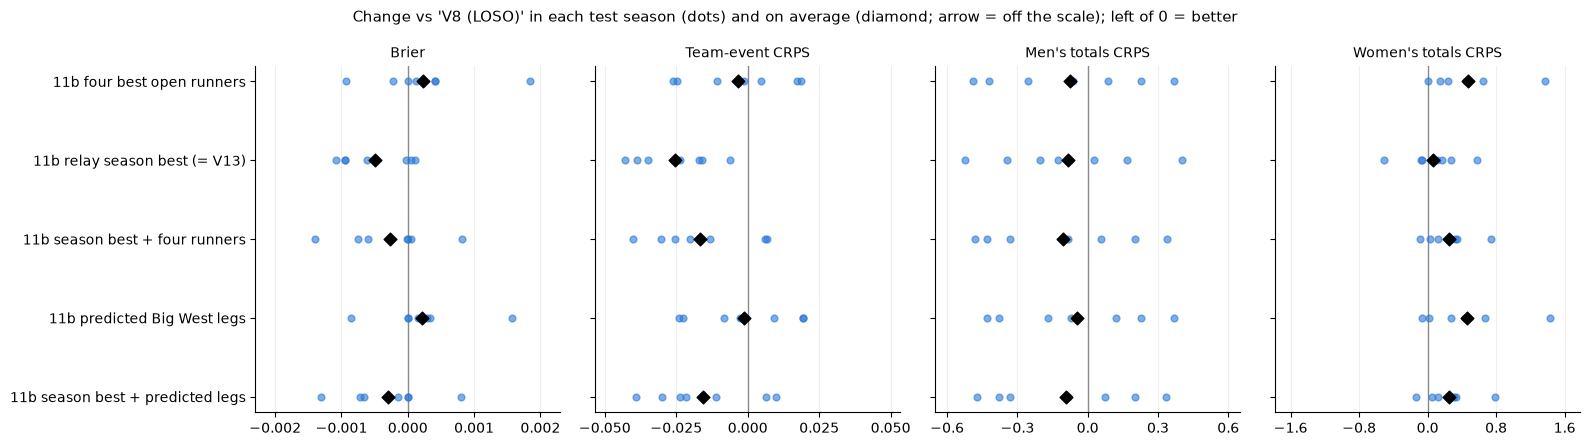

Relay points error per team per relay, by season:


test,2019,2021,2022,2023,2024,2025,2026,mean
V8 (LOSO),1.91,1.48,2.79,1.74,1.78,1.92,2.15,1.97
11b four best open runners,1.91,1.15,2.88,2.11,2.11,1.35,2.12,1.95
11b relay season best (= V13),1.69,1.11,2.00,1.77,1.33,1.05,1.59,1.51
11b season best + four runners,1.59,1.00,2.41,1.94,1.89,1.05,1.71,1.66
11b predicted Big West legs,1.88,1.22,2.85,2.14,2.11,1.35,2.22,1.97
11b season best + predicted legs,1.62,1.00,2.50,2.06,1.83,1.08,1.76,1.69
performance list,1.69,1.22,2.68,2.20,1.81,1.27,1.46,1.76


seasons better than the performance list: {'V8 (LOSO)': '2/7', '11b four best open runners': '2/7', '11b relay season best (= V13)': '5/7', '11b season best + four runners': '5/7', '11b predicted Big West legs': '1/7', '11b season best + predicted legs': '5/7'}


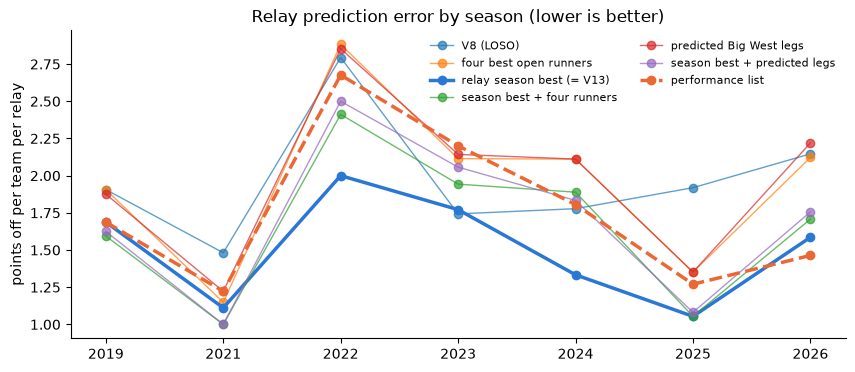

All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,11b four best open runners,W_total_crps_model,7.430,7.430,True
1,11b relay season best (= V13),te_crps_model,1.223,1.223,True
2,11b relay season best (= V13),M_total_crps_model,6.685,6.685,True
3,11b relay season best (= V13),W_total_crps_model,7.024,7.024,True
4,11b season best + four runners,W_total_crps_model,7.205,7.205,True
5,11b predicted Big West legs,W_total_crps_model,7.413,7.413,True


In [115]:
RELAY_OPTIONS = {
    "V8 (LOSO)": (V8, LOSO),
    "11b four best open runners": ({**V8, "relay_mu": "legs"}, LOSO),
    "11b relay season best (= V13)": (V13, LOSO),
    "11b season best + four runners": ({**V8, "relay_mu": "best_legs"}, LOSO),
    "11b predicted Big West legs": ({**V8, "relay_mu": "legs_bw"}, LOSO),
    "11b season best + predicted legs": ({**V8, "relay_mu": "best_legs_bw"}, LOSO),
}
step11b, mean11b = run_step("11b relay options", RELAY_OPTIONS)

lst = TE[TE["event"].isin(["4x100", "4x400"])].groupby("test")["performance list"].mean()
rel = pd.DataFrame({k: relay_error(k) for k in RELAY_OPTIONS}).T
rel.loc["performance list"] = lst
rel["mean"] = rel.mean(axis=1)
print("Relay points error per team per relay, by season:")
display(rel.round(2))
beats = {k: f"{int((rel.loc[k, ALL_SEASONS] < rel.loc['performance list', ALL_SEASONS]).sum())}/7" for k in RELAY_OPTIONS}
print("seasons better than the performance list:", beats)

fig, ax = plt.subplots(figsize=(10, 4))
for k in rel.index:
    style = dict(color=ORANGE, lw=2.5, ls="--") if k == "performance list" else (
        dict(color=BLUE, lw=2.5) if "season best (= V13)" in k else dict(lw=1, alpha=0.7))
    ax.plot([str(s) for s in ALL_SEASONS], rel.loc[k, ALL_SEASONS], marker="o", label=k.replace("11b ", ""), **style)
ax.set(ylabel="points off per team per relay", title="Relay prediction error by season (lower is better)")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.spines[["top", "right"]].set_visible(False)
plt.show()
check(mean11b, {
    ('11b four best open runners', 'W_total_crps_model'): 7.43,
    ('11b relay season best (= V13)', 'te_crps_model'): 1.223,
    ('11b relay season best (= V13)', 'M_total_crps_model'): 6.685,
    ('11b relay season best (= V13)', 'W_total_crps_model'): 7.024,
    ('11b season best + four runners', 'W_total_crps_model'): 7.205,
    ('11b predicted Big West legs', 'W_total_crps_model'): 7.413,
})

**Result**
- **Four best open runners** (with regular-season or predicted Big West times): no better than the relays' own
  races overall (1.95–1.97 vs 1.97), and women's totals get worse (6.96 → 7.41–7.43). Open times miss baton
  exchanges, flying starts and lineup choices (200 runners on the 4x100, 800 runners on the 4x400). Using the
  predicted Big West times changes almost nothing, because the shift from regular season to Big West is mostly the
  same for every runner and cancels out in the sum.
- **Relay season best:** relay error 1.97 → 1.51 points, better than the performance list in 5 of 7 seasons, and
  team-event CRPS better in 7/7 seasons.
- Averaging the season best with the runners is worse than the season best alone (1.66–1.69).

### 11c. Is the season-best result overfitting?
The season best was chosen after comparing six options on all seven seasons, so it needs checks that don't
depend on that choice:
1. **Past-only training:** each season predicted only from earlier seasons (the walk-forward folds and 2026).
2. **Consistency:** 7 seasons × men/women × 4x100/4x400 = 28 cases.
3. **Uncertainty:** a bootstrap interval for the improvement (resampling seasons, then teams).
4. **Honest ranges:** the relays' 80% ranges should still contain the real result about 80% of the time.

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V8 (walk-forward),2.253,-0.161,0.108,1.224,6.127,6.506,0.972,0.951
V13 (walk-forward),2.253,-0.161,0.108,1.199,6.217,6.807,0.969,0.942


Seasons where each version beats 'V8 (walk-forward)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V13 (walk-forward),0/4,4/4,4/4,1/4,0/4,0/4,1/4


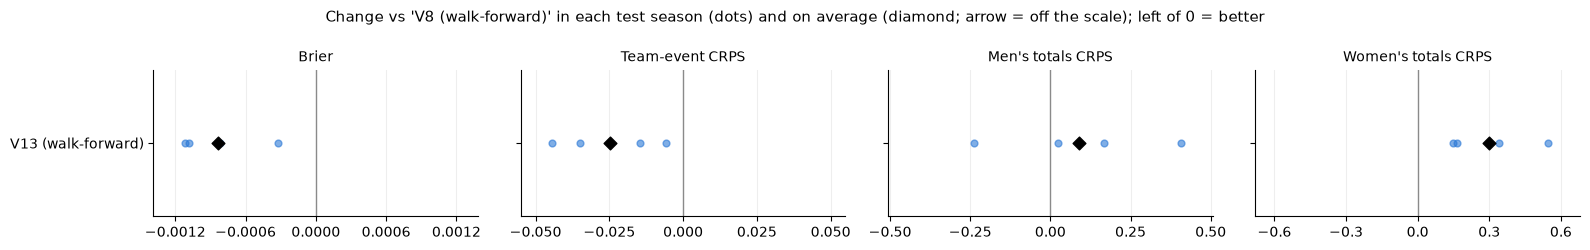

Relay points error, walk-forward:


test,2023,2024,2025,2026
V8 (walk-forward),1.83,1.89,2.00,2.15
V13 (walk-forward),1.89,1.50,1.05,1.59


season best better in 24 of 28 cases (1 ties); sign test p = 0.00002


better  mean
gender event             
M      4x100    6/7 -0.22
       4x400    6/7 -0.80
W      4x100    5/7 -0.09
       4x400    7/7 -0.70

change in relay points error per team per relay: -0.471 (95% interval -0.749 to -0.187)


,V8,V13
event,,
4x100,0.882,0.891
4x400,0.846,0.919


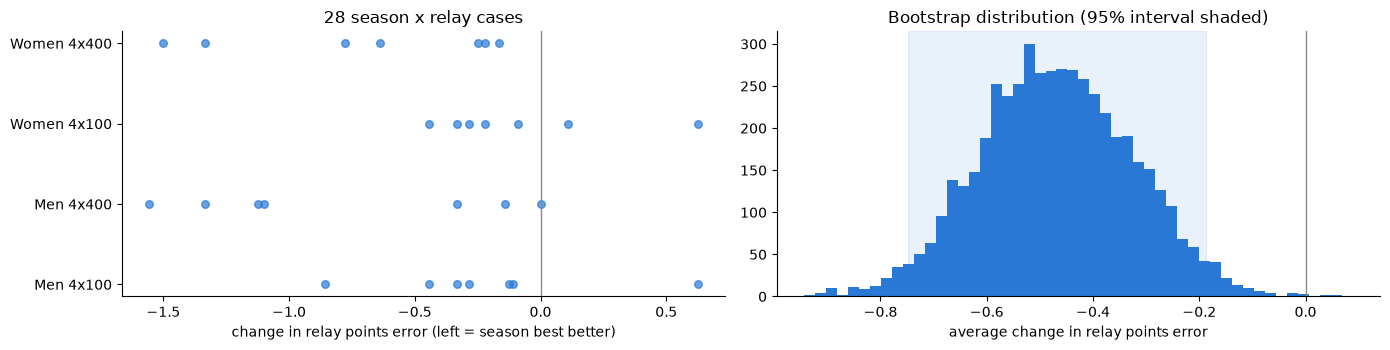

V8 (LOSO): correlation of relay error with the rest of the team's error = 0.05
V8 (walk-forward): correlation of relay error with the rest of the team's error = -0.13


In [116]:
# 1. past-only training
wf = {"V8 (walk-forward)": (V8, FOLDS + [FINAL_FOLD]), "V13 (walk-forward)": (V13, FOLDS + [FINAL_FOLD])}
step11c, mean11c = run_step("11c walk-forward", wf)
print("Relay points error, walk-forward:")
display(pd.DataFrame({k: relay_error(k) for k in wf}).T.round(2))

# 2. consistency over 28 cases
def relay_cells(label):
    te = pd.concat(r["team_event"].assign(test=t) for t, r in results[label].items())
    te = te[te["event"].isin(["4x100", "4x400"])]
    return te.assign(err=(te["med"] - te["actual"]).abs()).groupby(["test", "gender", "event"])["err"].mean()
cells = pd.DataFrame({"V8": relay_cells("V8 (LOSO)"), "V13": relay_cells("11b relay season best (= V13)")})
cells["change"] = cells["V13"] - cells["V8"]
nz = cells[~np.isclose(cells["change"], 0)]
p_sign = stats.binomtest(int((nz["change"] < 0).sum()), len(nz), 0.5, alternative="greater").pvalue
print(f"season best better in {(cells['change'] < 0).sum()} of {len(cells)} cases "
      f"({np.isclose(cells['change'], 0).sum()} ties); sign test p = {p_sign:.5f}")
display(cells.groupby(["gender", "event"])["change"].agg(better=lambda s: f"{(s < 0).sum()}/{len(s)}", mean="mean").round(2))

# 3. bootstrap interval (resample seasons, then team-relays within each season)
def team_relay(label):
    te = pd.concat(r["team_event"].assign(test=t) for t, r in results[label].items())
    te = te[te["event"].isin(["4x100", "4x400"])]
    return te.assign(err=(te["med"] - te["actual"]).abs()).set_index(["test", "gender", "event", "team"])["err"]
d = (team_relay("11b relay season best (= V13)") - team_relay("V8 (LOSO)")).dropna().reset_index(name="diff")
rng = np.random.default_rng(0)
boots = []
for _ in range(5000):
    parts = [d[d["test"] == s]["diff"].to_numpy() for s in rng.choice(ALL_SEASONS, len(ALL_SEASONS))]
    boots.append(np.concatenate([x[rng.integers(0, len(x), len(x))] for x in parts]).mean())
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"change in relay points error per team per relay: {d['diff'].mean():.3f} (95% interval {lo:.3f} to {hi:.3f})")

# 4. 80% coverage of relay results
def coverage(label):
    te = pd.concat(r["team_event"] for r in results[label].values())
    te = te[te["event"].isin(["4x100", "4x400"])]
    return ((te["actual"] >= te["lo80"]) & (te["actual"] <= te["hi80"])).groupby(te["event"]).mean()
display(pd.DataFrame({"V8": coverage("V8 (LOSO)"), "V13": coverage("11b relay season best (= V13)")}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
cl = cells.reset_index()
for k, (g, e) in enumerate([("M", "4x100"), ("M", "4x400"), ("W", "4x100"), ("W", "4x400")]):
    c = cl[(cl["gender"] == g) & (cl["event"] == e)]
    axes[0].scatter(c["change"], [k] * len(c), color=BLUE, s=30, alpha=0.7)
axes[0].axvline(0, color=GRAY, lw=1)
axes[0].set_yticks(range(4), ["Men 4x100", "Men 4x400", "Women 4x100", "Women 4x400"])
axes[0].set(xlabel="change in relay points error (left = season best better)", title="28 season x relay cases")
axes[1].hist(boots, bins=50, color=BLUE)
axes[1].axvline(0, color=GRAY, lw=1)
axes[1].axvspan(lo, hi, color=BLUE, alpha=0.1)
axes[1].set(xlabel="average change in relay points error", title="Bootstrap distribution (95% interval shaded)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

# why team totals don't follow: relay errors vs the rest of the team's error, same team-season
def team_errors(label):
    te = pd.concat(r["team_event"].assign(test=t) for t, r in results[label].items())
    te["part"] = np.where(te["event"].isin(["4x100", "4x400"]), "relay", "other")
    return te.assign(e=te["med"] - te["actual"]).groupby(["test", "gender", "team", "part"])["e"].sum().unstack()
for lab in ["V8 (LOSO)", "V8 (walk-forward)"]:
    t_ = team_errors(lab)
    print(f"{lab}: correlation of relay error with the rest of the team's error = {t_['relay'].corr(t_['other']):.2f}")

**Result: the season-best gain is real, not a product of choosing the best option.**
- **Past-only training:** relay error is lower in 3 of 4 seasons (2024–2026, much lower; 2023 slightly higher),
  and Brier and team-event CRPS are better in 4/4.
- **Consistency:** better in 24 of 28 season × relay cases (1 tie), including women's 4x400 in 7/7. A coin flip
  would almost never give this (p = 0.00002), even allowing for six options tried.
- **Uncertainty:** relay error drops by 0.47 points per team per relay, 95% interval 0.19 to 0.75.
- **Honest ranges:** 80% coverage of relay results is 89% / 92% (4x100 / 4x400), against 88% / 85% before.
- **Why team totals don't follow:** in the 2023–2026 seasons the old relay errors happened to offset errors in the
  same team's other events (correlation −0.13); fixing the relays removed that accidental cancellation. Over seven
  seasons there is no such pattern (0.05).

### 11d. Final model: V8 + relays centred on their season best (V13)

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V8,2.331,-0.161,0.107,1.227,6.257,5.430,0.963,0.960
V13 final,2.331,-0.161,0.107,1.206,6.321,5.776,0.963,0.956


Seasons where each version beats 'V8' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V13 final,0/3,3/3,3/3,1/3,0/3,0/3,1/3


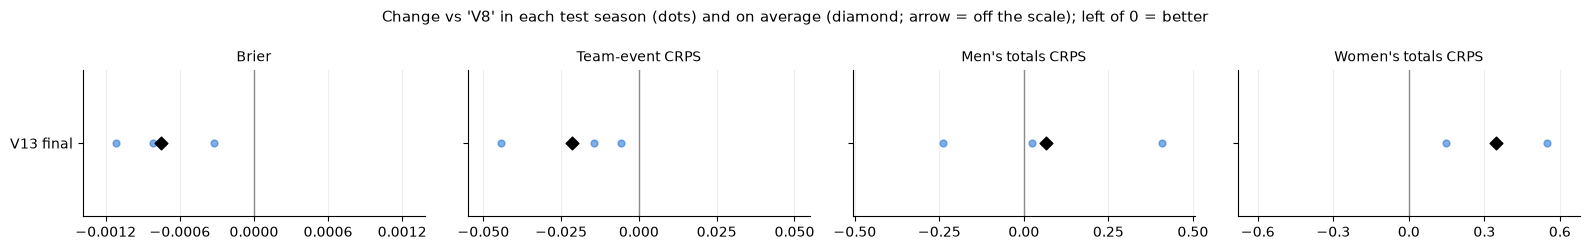

Seven seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V8 (LOSO),2.327,-0.165,0.118,1.249,6.771,6.956,0.968,0.896
11b relay season best (= V13),2.327,-0.165,0.117,1.223,6.685,7.024,0.967,0.891


All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V13 final,te_crps_model,1.206,1.206,True
1,V13 final,M_total_crps_model,6.321,6.321,True
2,V13 final,W_total_crps_model,5.776,5.776,True


In [117]:
step11d, mean11d = run_step("11d final model", {
    "V8": (V8, FOLDS),
    "V13 final": (V13, FOLDS),
})
print("Seven seasons:")
display(mean11b.loc[["V8 (LOSO)", "11b relay season best (= V13)"]].round(3))
check(mean11d, {
    ('V13 final', 'te_crps_model'): 1.206,
    ('V13 final', 'M_total_crps_model'): 6.321,
    ('V13 final', 'W_total_crps_model'): 5.776,
})

**Result and decision: V13 is the final model.**
- On the validation folds, relays make Brier and team-event CRPS better in 3/3 folds, but team totals worse than V8
  (men 6.26 → 6.32, 1/3; women 5.43 → 5.78, 0/3). This fails the keep rule on team totals.
- Over seven seasons men's totals improve (6.77 → 6.69) and women's are about level (6.96 → 7.02).
- On the seasons never used for selection (9a), V13 is the best version on team totals.
- **Kept for relay accuracy and realism:** teams run their strongest four at the championship. The team-total loss
  on the validation folds is explained by the cancellation in 11c and is stated as a limitation.

# Part 7. Final model
## Step 12. The final model on 2026, and the path from V1
2026 was held out until step 7 (V5). V8 and V13 were chosen afterwards, partly using seven-season results that
include 2026, so their 2026 numbers are **after the fact**: shown for completeness, not as a clean test.

,V5 (holdout),"V13 final, after the fact",performance list
mark MAE %,2.020,2.017,NaN
mark bias %,-0.180,-0.163,NaN
Brier,0.112,0.110,0.185
team-event points off,1.710,1.622,1.898
men's totals off,8.000,8.600,14.200
women's totals off,13.909,14.182,10.455
men's ranking,1.000,0.988,0.891
women's ranking,0.902,0.902,0.936


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
V1,2.365,0.005,0.109,1.234,6.666,5.721,0.952,0.964
V2,2.349,-0.019,0.109,1.241,6.572,5.679,0.957,0.964
V3,2.349,-0.019,0.109,1.238,6.428,5.712,0.963,0.964
V4,2.329,-0.156,0.108,1.233,6.435,5.556,0.963,0.960
V5,2.329,-0.156,0.108,1.232,6.364,5.527,0.963,0.960
V8,2.331,-0.161,0.107,1.227,6.257,5.430,0.963,0.960
V13,2.331,-0.161,0.107,1.206,6.321,5.776,0.963,0.956


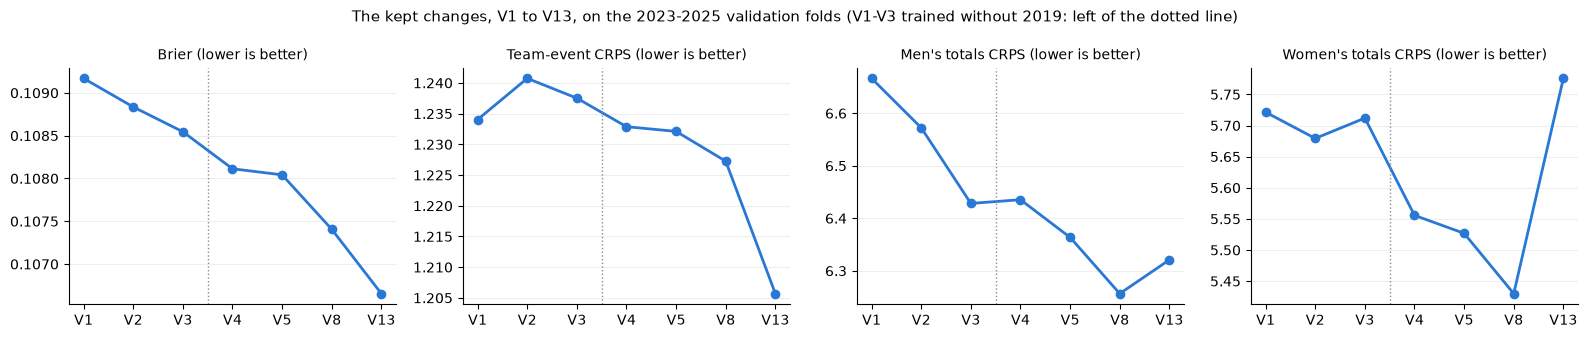

In [118]:
final_v13 = bm.run_fold(reg, bw, *FINAL_FOLD, cdates, bw_events, {**CFG, **V13}, verbose=False)
s13 = final_v13["summary"]
holdout["V13 final, after the fact"] = pd.Series({
    "mark MAE %": s13["mark_mae_pct"], "mark bias %": s13["mark_bias_pct"], "Brier": s13["brier_model"],
    "team-event points off": s13["te_mae_model"], "men's totals off": s13["M_total_mae_model"],
    "women's totals off": s13["W_total_mae_model"], "men's ranking": s13["M_spearman_model"],
    "women's ranking": s13["W_spearman_model"]})
display(holdout[["model, entrants", "V13 final, after the fact", "performance list"]]
        .rename(columns={"model, entrants": "V5 (holdout)"}).round(3))

# the kept path, on the validation folds (V1-V3 were trained without 2019)
path = {"V1": "V1 original", "V2": "V2 + athlete offset", "V3": "V3 + athlete failure chance",
        "V4": "V4 = V3 + 2019 in training", "V5": "V5 two rounds, measured rho", "V8": "V8 all data-based settings",
        "V13": "V13 final"}
pm = pd.DataFrame({k: pd.DataFrame([r["summary"] for r in results[v].values()])[COLS].mean() for k, v in path.items()}).T
display(pm.round(3))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (col, name) in zip(axes, PLOT):
    ax.plot(pm.index, pm[col], marker="o", color=BLUE, lw=2)
    ax.axvline(2.5, color=GRAY, ls=":", lw=1)
    ax.set_title(f"{name} (lower is better)", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#eeeeee")
fig.suptitle("The kept changes, V1 to V13, on the 2023-2025 validation folds (V1-V3 trained without 2019: left of the dotted line)",
             fontsize=11)
fig.tight_layout(); plt.show()

**Result**
- On 2026 (after the fact), V13 is better than V5 on Brier (0.110 vs 0.112) and team-event points (1.62 vs 1.71 off),
  and slightly worse on team totals (men 8.6 vs 8.0, women 14.2 vs 13.9 off). Both beat the performance list
  everywhere except women's totals.
- **The kept path:** 2019 in training (V4) and the athlete-specific failure chance (V3) gave the largest gains on
  team totals; V8 added a small consistent gain; V13 improves Brier and team-event accuracy most, at a cost in
  women's totals on these three folds (see 11d).

### Ablation: does every kept piece still help in the final model?
Each change was kept because it beat the model *at the time*, so an early change could look useful only because
of what came before or after it. Here each kept piece is removed from the final model in turn, on all seven
seasons. If removing a piece makes the model worse, it earns its place regardless of the order things were added.
In this chart **right of zero means removing the piece makes the model worse** (so the piece helps).

Mean over the test seasons:


,mark_mae_pct,mark_bias_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
version,,,,,,,,
V13 final (LOSO),2.327,-0.165,0.117,1.223,6.685,7.024,0.967,0.891
without athlete offset (V2),2.335,-0.159,0.117,1.223,6.780,6.983,0.964,0.890
without athlete failure chance (V3),2.327,-0.165,0.118,1.228,6.781,7.077,0.968,0.893
without 2019 in training (V4),2.337,-0.106,0.118,1.227,6.758,7.088,0.967,0.893
without two rounds (V5),2.327,-0.165,0.117,1.224,6.714,7.015,0.967,0.893
without V8 settings,2.325,-0.182,0.118,1.228,6.728,7.106,0.969,0.888
without relay season best (= V8),2.327,-0.165,0.118,1.249,6.771,6.956,0.968,0.896


Seasons where each version beats 'V13 final (LOSO)' (lower is better except Spearman):


,mark_mae_pct,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
without athlete offset (V2),3/7,3/7,4/7,3/7,3/7,1/7,1/7
without athlete failure chance (V3),0/7,1/7,1/7,2/7,4/7,2/7,1/7
without 2019 in training (V4),0/7,1/7,1/7,2/7,0/7,0/7,1/7
without two rounds (V5),0/7,2/7,1/7,2/7,4/7,0/7,1/7
without V8 settings,6/7,1/7,1/7,2/7,2/7,1/7,0/7
without relay season best (= V8),0/7,2/7,0/7,3/7,4/7,2/7,2/7


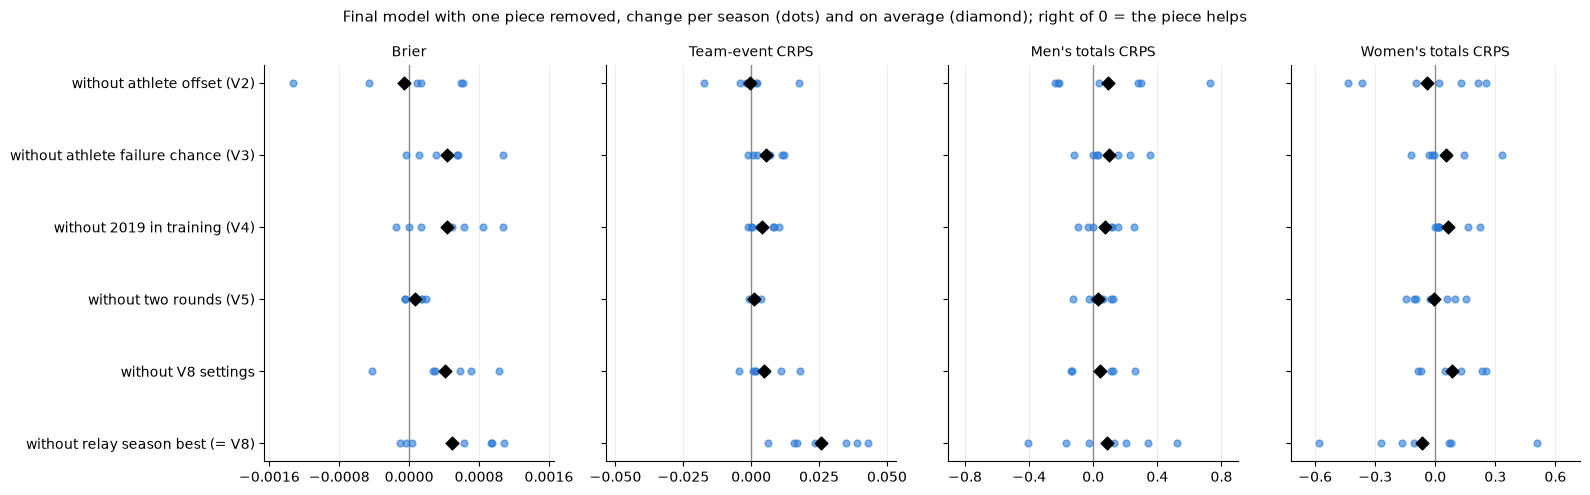

(In the 'beats' table above, a low count means the final model WITH the piece is better in most seasons.)
All recorded numbers reproduced.


,version,metric,recorded,reproduced,match
0,V13 final (LOSO),M_total_crps_model,6.685,6.685,True
1,V13 final (LOSO),W_total_crps_model,7.024,7.024,True
2,without athlete offset (V2),M_total_crps_model,6.780,6.780,True
3,without athlete offset (V2),W_total_crps_model,6.983,6.983,True
4,without athlete failure chance (V3),te_crps_model,1.228,1.228,True
5,without athlete failure chance (V3),M_total_crps_model,6.781,6.781,True
6,without 2019 in training (V4),mark_mae_pct,2.337,2.337,True
7,without 2019 in training (V4),W_total_crps_model,7.088,7.088,True
8,without two rounds (V5),M_total_crps_model,6.714,6.714,True
9,without V8 settings,W_total_crps_model,7.106,7.106,True


In [119]:
LOSO_NO_2019 = [([s for s in train if s != 2019], test) for train, test in LOSO]
step12_abl, mean12_abl = run_step("12 ablation", {
    "V13 final (LOSO)": (FINAL, LOSO),
    "without athlete offset (V2)": ({**FINAL, "offset_model": "event"}, LOSO),
    "without athlete failure chance (V3)": ({**FINAL, "pfail_model": "event"}, LOSO),
    "without 2019 in training (V4)": (FINAL, LOSO_NO_2019),
    "without two rounds (V5)": ({**FINAL, "two_rounds": False}, LOSO),
    "without V8 settings": ({**FINAL, "k_spread": 4, "cal_prior_n": 8, "dns_as_fail": True, "impute_sd_mult": 1.5}, LOSO),
    "without relay season best (= V8)": (V8, LOSO),
}, title="Final model with one piece removed, change per season (dots) and on average (diamond); right of 0 = the piece helps")
print("(In the 'beats' table above, a low count means the final model WITH the piece is better in most seasons.)")
check(mean12_abl, {
    ('V13 final (LOSO)', 'M_total_crps_model'): 6.685,
    ('V13 final (LOSO)', 'W_total_crps_model'): 7.024,
    ('without athlete offset (V2)', 'M_total_crps_model'): 6.78,
    ('without athlete offset (V2)', 'W_total_crps_model'): 6.983,
    ('without athlete failure chance (V3)', 'te_crps_model'): 1.228,
    ('without athlete failure chance (V3)', 'M_total_crps_model'): 6.781,
    ('without 2019 in training (V4)', 'mark_mae_pct'): 2.337,
    ('without 2019 in training (V4)', 'W_total_crps_model'): 7.088,
    ('without two rounds (V5)', 'M_total_crps_model'): 6.714,
    ('without V8 settings', 'W_total_crps_model'): 7.106,
    ('without relay season best (= V8)', 'te_crps_model'): 1.249,
})

**Result**

| Piece removed | Brier | Team-event CRPS | Men's totals | Women's totals | Verdict |
|---|---|---|---|---|---|
| Athlete-specific failure chance (V3) | worse 6/7 | worse 6/7 | worse 5/7 (6.69 → 6.78) | worse on average (7.02 → 7.08), 3/7 | **earns its place** |
| 2019 in training (V4) | worse 5/7 | worse 5/7 | worse 4/7 | worse 6/7 (7.02 → 7.09) | **earns its place** |
| V8 settings | worse 6/7 | worse 6/7 | worse 5/7 | worse 5/7 (7.02 → 7.11) | **earns its place** |
| Two rounds (V5) | worse 5/7 | worse 6/7 | worse 5/7 (6.69 → 6.71) | about level (7.02 vs 7.02) | earns its place, small |
| Relay season best (V13) | worse 5/7 | worse 7/7 | worse 4/7 | better without it (6.96) | earns its place on events, not on women's totals |
| Athlete-specific offset (V2) | about level | level | worse 4/7 (6.69 → 6.78) | better without it on average (6.98), though the final model is better in 4/7 | **weakest piece** |

- Five of the six kept pieces still help in the final model. The failure chance, 2019 and the V8 settings help on
  every measure.
- **The athlete-specific offset (V2) is the order effect in action.** It was the first change added, and much of
  what it captured is now covered by later pieces (the failure model uses the same features; V8 changes how the
  spread is measured). In the final model it still helps men's totals and mark error, but not women's totals.
  It is kept: removing it would make men's totals and the predicted marks worse, and its coefficients are
  stable and make sense (8a, step 1). Its contribution should be described as modest.

# Full history table (saved for the write-up)

In [120]:
history = pd.concat(per_fold_all, ignore_index=True).drop_duplicates(["version", "test"])
history_mean = history.groupby(["step", "version"], sort=False)[COLS].mean().round(3)
display(history_mean)

OUT_DIR.mkdir(exist_ok=True)
history.to_csv(OUT_DIR / "model_history_per_fold.csv", index=False)
history_mean.to_csv(OUT_DIR / "model_history_mean.csv")
holdout.round(4).to_csv(OUT_DIR / "holdout_2026.csv")
print(f"saved to {OUT_DIR.resolve()}")

mark_mae_pct  mark_bias_pct  brier_model  te_crps_model  M_total_crps_model  W_total_crps_model  M_spearman_model  W_spearman_model
step            version                                                                                                                                                                 
1 hybrid + 2019 V1 original                                 2.365          0.005        0.109          1.234               6.666               5.721             0.952             0.964
                V2 + athlete offset                         2.349         -0.019        0.109          1.241               6.572               5.679             0.957             0.964
                V3 + athlete failure chance                 2.349         -0.019        0.109          1.238               6.428               5.712             0.963             0.964
                V4 = V3 + 2019 in training                  2.329         -0.156        0.108          1.233               6.435               5.556             0.963             0.960
2 two rounds    V4 (one round)                              2.329         -0.156        0.108          1.233               6.435               5.556             0.963             0.960
...                                                           ...            ...          ...            ...                 ...                 ...               ...               ...
12 ablation     without athlete failure chance (V3)         2.327         -0.165        0.118          1.228               6.781               7.077             0.968             0.893
                without 2019 in training (V4)               2.337         -0.106        0.118          1.227               6.758               7.088             0.967             0.893
                without two rounds (V5)                     2.327         -0.165        0.117          1.224               6.714               7.015             0.967             0.893
                without V8 settings                         2.325         -0.182        0.118          1.228               6.728               7.106             0.969             0.888
                without relay season best (= V8)            2.327         -0.165        0.118          1.249               6.771               6.956             0.968             0.896

[99 rows x 8 columns]

saved to C:\Users\12094\DSC180\big-west-predictor\results
